# Clase 5A — Tutorial: calibración de imágenes FORS2 de NGC 6121 (M4)

**Laboratorio de Astronomía I — Unidad 5: Fotometría**

En este tutorial vamos a tomar las imágenes **crudas** (tal como salen del telescopio) del cúmulo globular **NGC 6121 (M4)** en el filtro **v_HIGH** y las vamos a convertir, paso a paso, en imágenes **calibradas** listas para hacer fotometría. Al final, combinaremos todas las exposiciones en una sola imagen profunda (*stacking*).

Los datos fueron tomados con **FORS2** en el telescopio **VLT (UT1)** de Paranal en junio de 2012 (programa ESO 089.D-0978) y son parte de los datos usados por **Nardiello et al. (2015, A&A 573, A70)** para estudiar poblaciones estelares múltiples en las **regiones externas** de M4 (por eso el campo no está centrado en el cúmulo).

### Lo que vamos a hacer

| Paso | Qué hacemos | Concepto de la clase |
|---|---|---|
| 1 | Preparar el entorno y descomprimir los archivos | — |
| 2 | Leer los *headers* y entender **cómo se tomó la observación** | headers FITS, OB, *jitter* |
| 3 | Mirar una imagen cruda por dentro | prescan, overscan, zona no iluminada, saturación |
| 4 | **Bias**: master bias y ruido de lectura | B |
| 5 | **Dark**: ¿lo necesitamos? | D·t |
| 6 | **Flat**: master flat normalizado | F |
| 7 | Calibrar **una** imagen de ciencia paso a paso | (RAW − B) / F |
| 8 | Imagen de **error** (incertidumbre de cada pixel) | ecuación del CCD |
| 9 | Calibrar **todas** las imágenes y guardarlas | — |
| 10 | **Combinar** las 25 exposiciones (*stacking*) | WCS, alineación, sigma-clipping |
| 11 | Puntos de control y ejercicios | — |

> **Recuerden la ecuación de la clase:**
> $$\text{RAW} = F \cdot (\text{Objeto} + \text{Cielo}) + D\cdot t + B \quad\Longrightarrow\quad \text{Objeto} + \text{Cielo} = \frac{\text{RAW} - B - D\cdot t}{F}$$

Todas las correcciones matemáticas las haremos **con numpy**, para que vean exactamente qué operación se hace sobre cada pixel.

> **Cómo leer este notebook:** antes de las celdas que usan funciones poco comunes hay un recuadro **🔎 Funciones nuevas en la celda siguiente** que explica qué hace cada una. Al final hay un **glosario** con todas.


---
## Paso 1 — Preparar el entorno

### 1.1 Paquetes que necesitamos

Si les falta alguno, ejecuten en una celda (o en la terminal):

```
pip install numpy matplotlib astropy photutils unlzw3
```

* `numpy`: operaciones con arreglos (las imágenes son arreglos 2D).
* `matplotlib`: gráficos.
* `astropy`: leer archivos FITS, headers, coordenadas (WCS) y estadística robusta.
* `photutils`: detectar estrellas (lo usaremos solo en el paso 10).
* `unlzw3`: descomprimir los archivos `.fits.Z` (ver 1.3).

#### 🔎 Funciones nuevas en la celda siguiente

Aquí solo **importamos** las herramientas que usaremos. Dos detalles poco comunes:

| Línea | Qué hace |
|---|---|
| `from astropy.io import fits` | Trae solo el módulo `fits` del paquete `astropy`, para escribir `fits.open(...)` en vez de `astropy.io.fits.open(...)`. |
| `import astropy.units as u` | Unidades físicas. Permite escribir `2 * u.arcsec` (2 segundos de arco) y que astropy haga las conversiones. |
| `warnings.simplefilter("ignore")` | Oculta los avisos (*warnings*). Los headers de ESO tienen palabras clave fuera del estándar FITS y astropy avisa muchas veces; no son errores. |
| `plt.rcParams["image.origin"] = "lower"` | Cambia una opción por defecto de matplotlib: el pixel (0, 0) se dibuja **abajo** a la izquierda (convención astronómica), no arriba como en una foto. |

In [1]:
import os
import glob

import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from astropy.visualization import ZScaleInterval, ImageNormalize, simple_norm
from astropy.coordinates import SkyCoord
import astropy.units as u

import unlzw3

import warnings
warnings.simplefilter("ignore")   # los headers de FORS2 generan avisos que no importan

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["image.origin"] = "lower"   # el pixel (0, 0) abajo a la izquierda, como en astronomía

### 1.2 Dónde están los datos

Este notebook debe estar en la carpeta `Notebooks/U5/`. Los datos están en `Notebooks/U5/NGC6121/NGC6121/`, organizados así:

```
NGC6121/NGC6121/
├── BIAS/                   bias de varias noches (todos los filtros)
├── FLAT/v_HIGH/            flats de cielo (crepúsculo) en el filtro v_HIGH
├── SCIENCE/v_HIGH/         imágenes del cúmulo en v_HIGH
├── STANDARD/v_HIGH/        estrellas estándar (las usaremos en la clase 5B)
└── CALIB_TABLES/           tablas de ESO (extinción, coeficientes fotométricos)
```

Los resultados de este tutorial se guardarán en una carpeta nueva `productos_v_HIGH/`.

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace | Ejemplo |
|---|---|---|
| `os.path.join(a, b)` | Une nombres de carpetas con el separador correcto del sistema operativo (`\` en Windows, `/` en Mac/Linux). | `os.path.join("NGC6121", "BIAS")` → `"NGC6121/BIAS"` |
| `os.makedirs(carpeta, exist_ok=True)` | Crea una carpeta (y las intermedias). Con `exist_ok=True` **no da error** si ya existe. | |
| `glob.glob(patrón)` | Busca archivos cuyo nombre calza con un patrón. El `*` significa "cualquier texto". | `glob.glob("BIAS/*.fits.Z")` → lista de todos los bias |
| `sorted(lista)` | Ordena la lista. Como los nombres de FORS2 incluyen la fecha y la hora, quedan en **orden cronológico**. | |

In [2]:
CARPETA_DATOS = os.path.join("NGC6121", "NGC6121")       # datos originales (no se modifican)
CARPETA_SALIDA = "productos_v_HIGH"                       # aquí guardamos todo lo que produzcamos
CARPETA_CRUDOS = os.path.join(CARPETA_SALIDA, "crudos")   # archivos descomprimidos
CARPETA_CALIB = os.path.join(CARPETA_SALIDA, "calibradas")

for carpeta in [CARPETA_SALIDA, CARPETA_CRUDOS, CARPETA_CALIB]:
    os.makedirs(carpeta, exist_ok=True)

FILTRO = "v_HIGH"

archivos_bias = sorted(glob.glob(os.path.join(CARPETA_DATOS, "BIAS", "*.fits.Z")))
archivos_flat = sorted(glob.glob(os.path.join(CARPETA_DATOS, "FLAT", FILTRO, "*.fits.Z")))
archivos_ciencia = sorted(glob.glob(os.path.join(CARPETA_DATOS, "SCIENCE", FILTRO, "*.fits.Z")))

print("Archivos de bias:   ", len(archivos_bias))
print("Archivos de flat:   ", len(archivos_flat))
print("Archivos de ciencia:", len(archivos_ciencia))

Archivos de bias:    22
Archivos de flat:    10
Archivos de ciencia: 50


### 1.3 Los archivos vienen comprimidos (`.fits.Z`)

El archivo de ESO entrega los datos comprimidos con el formato `.Z` (el antiguo programa `compress` de Unix). `astropy` no abre ese formato directamente, así que primero los **descomprimimos** con el paquete `unlzw3` y guardamos una copia `.fits` normal en `productos_v_HIGH/crudos/`.

Esto se hace **una sola vez**: la segunda vez que ejecuten el notebook, la función encuentra el `.fits` ya descomprimido y lo abre directamente. La primera vez puede tardar uno o dos minutos.

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `os.path.basename(ruta)` | Se queda solo con el nombre del archivo, sin las carpetas: `"NGC6121/BIAS/FORS2...fits.Z"` → `"FORS2...fits.Z"`. |
| `texto.replace(a, b)` | Reemplaza un pedazo de texto: aquí cambia `.fits.Z` por `.fits`. |
| `os.path.exists(ruta)` | `True` si el archivo ya existe. Así descomprimimos **solo la primera vez**. |
| `with open(ruta, "rb") as f:` | Abre un archivo en modo binario (`"rb"` = leer bytes, `"wb"` = escribir bytes) y lo cierra solo al terminar el bloque. |
| `unlzw3.unlzw(bytes)` | Descomprime datos en formato `.Z` (algoritmo LZW) y devuelve los bytes del FITS original. |
| `fits.open(ruta)[0]` | Abre el FITS. Un FITS puede tener varias "extensiones" (HDU); la `[0]` es la principal. Tiene `.data` (la imagen) y `.header`. |
| `.astype(np.float32)` | Convierte los números a **decimales**. Los datos crudos son enteros, y con enteros las restas y divisiones perderían los decimales. |

In [3]:
def abrir_fits(ruta_Z):
    # Descomprime (si hace falta) un archivo .fits.Z y devuelve (datos, header).
    nombre = os.path.basename(ruta_Z).replace(".fits.Z", ".fits")
    ruta_fits = os.path.join(CARPETA_CRUDOS, nombre)

    # 1) si todavía no existe la versión descomprimida, la creamos
    if not os.path.exists(ruta_fits):
        with open(ruta_Z, "rb") as f:
            contenido = unlzw3.unlzw(f.read())
        with open(ruta_fits, "wb") as f:
            f.write(contenido)

    # 2) abrimos el FITS normal
    hdu = fits.open(ruta_fits)[0]
    datos = hdu.data.astype(np.float32)   # convertimos a decimales para poder restar y dividir
    return datos, hdu.header


datos, header = abrir_fits(archivos_ciencia[0])
print("Tamaño de la imagen (filas, columnas):", datos.shape)
print("Tipo de dato:", datos.dtype)

Tamaño de la imagen (filas, columnas): (1034, 2048)
Tipo de dato: float32


---
## Paso 2 — ¿Cómo se tomó la observación? Leer los headers

Cada archivo FITS tiene un **header**: un "encabezado" de texto con cientos de palabras clave (*keywords*) que describen la observación. Antes de tocar los pixeles, siempre hay que leerlo.

### 2.1 Palabras clave importantes de FORS2

| Keyword | Significado |
|---|---|
| `OBJECT` | nombre del objeto (o `BIAS`, `FLAT,SKY`, ...) |
| `HIERARCH ESO DPR TYPE` | tipo de imagen: `BIAS`, `FLAT,SKY`, `OBJECT`, `STD` |
| `EXTNAME` | **chip**: FORS2 tiene 2 CCD (`CHIP1` arriba y `CHIP2` abajo) |
| `HIERARCH ESO INS FILT1 NAME` | filtro |
| `EXPTIME` | tiempo de exposición [s] |
| `DATE-OBS` | fecha y hora (UT) del inicio de la exposición |
| `HIERARCH ESO TEL AIRM START` | masa de aire al inicio |
| `HIERARCH ESO TEL AMBI FWHM START` | seeing medido por el DIMM [″] |
| `HIERARCH ESO OBS NAME` | nombre del **Observing Block (OB)** |
| `HIERARCH ESO TPL NAME` | **template** (receta de observación) |
| `HIERARCH ESO TPL EXPNO` / `TPL NEXP` | número de esta exposición dentro del template / total |
| `HIERARCH ESO DET WIN1 BINX` | *binning* (2 = se suman 2×2 pixeles) |
| `HIERARCH ESO DET OUT1 CONAD` | **ganancia** [e⁻/ADU] |
| `HIERARCH ESO DET OUT1 RON` | **ruido de lectura** [e⁻] |
| `HIERARCH ESO DET OUT1 PRSCY` / `OVSCY` | filas de **prescan** / **overscan** |
| `RA`, `DEC` | coordenadas del apuntado [grados] |
| `CRVAL`, `CRPIX`, `CD` | la solución astrométrica (**WCS**) |

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `header.get(clave)` | Lee el valor de una palabra clave del header. Si no existe, devuelve `None` en vez de dar error (con `header[clave]` sí daría error). |
| `header.get(clave, valor)` | Igual, pero si no existe devuelve `valor` (lo usamos más adelante con `np.nan`). |
| `print(f"...")` | Un **f-string**: lo que va entre `{ }` se reemplaza por su valor. `{clave:36s}` rellena el texto hasta 36 caracteres (para que todo quede alineado); `{x:.2f}` muestra un número con 2 decimales. |
| `"-" * 60` | Repite el texto 60 veces: una línea separadora. |

In [4]:
claves = ["OBJECT", "EXTNAME", "EXPTIME", "DATE-OBS", "RA", "DEC",
          "HIERARCH ESO DPR TYPE", "HIERARCH ESO INS FILT1 NAME",
          "HIERARCH ESO OBS NAME", "HIERARCH ESO TPL NAME",
          "HIERARCH ESO TPL EXPNO", "HIERARCH ESO TPL NEXP",
          "HIERARCH ESO TEL AIRM START", "HIERARCH ESO TEL AMBI FWHM START",
          "HIERARCH ESO DET WIN1 BINX", "HIERARCH ESO INS PIXSCALE",
          "HIERARCH ESO DET OUT1 CONAD", "HIERARCH ESO DET OUT1 RON",
          "HIERARCH ESO DET OUT1 PRSCY", "HIERARCH ESO DET OUT1 OVSCY"]

print("Header de:", os.path.basename(archivos_ciencia[0]))
print("-" * 60)
for clave in claves:
    print(f"{clave:36s} = {header.get(clave)}")

Header de: FORS2.2012-06-15T00_46_28.474.fits.Z
------------------------------------------------------------
OBJECT                               = NGC6121_V
EXTNAME                              = CHIP1
EXPTIME                              = 52.0025
DATE-OBS                             = 2012-06-15T00:46:28.473
RA                                   = 245.807667
DEC                                  = -26.40372
HIERARCH ESO DPR TYPE                = OBJECT
HIERARCH ESO INS FILT1 NAME          = v_HIGH
HIERARCH ESO OBS NAME                = NGC6121_Vnew
HIERARCH ESO TPL NAME                = jitter images
HIERARCH ESO TPL EXPNO               = 1
HIERARCH ESO TPL NEXP                = 25
HIERARCH ESO TEL AIRM START          = 1.251
HIERARCH ESO TEL AMBI FWHM START     = 0.69
HIERARCH ESO DET WIN1 BINX           = 2
HIERARCH ESO INS PIXSCALE            = 0.126
HIERARCH ESO DET OUT1 CONAD          = 1.25
HIERARCH ESO DET OUT1 RON            = 2.7
HIERARCH ESO DET OUT1 PRSCY          = 5
HIERA

**Algunas cosas que ya podemos decir:**

* El binning es **2×2** y la escala de FORS2 sin binning es 0,126″/pixel, así que cada pixel de nuestras imágenes mide **≈ 0,25″**.
* La ganancia es **1,25 e⁻/ADU**: cada cuenta (ADU) corresponde a 1,25 electrones.
* El ruido de lectura es de **2,7 e⁻** en el CHIP1 (en el CHIP2 es 3,6 e⁻: cada chip es distinto).
* Hay **5 filas de prescan y 5 de overscan**: no reciben luz y hay que recortarlas.
* El template se llama `jitter images` y tiene **25 exposiciones**: la observación es una secuencia de 25 imágenes con pequeños desplazamientos del telescopio entre una y otra.

### 2.2 Inventario de todos los archivos

Ahora leemos el header de **todos** los archivos y armamos una tabla. Así sabemos exactamente qué tenemos antes de calibrar.

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `{"clave": valor, ...}` | Un **diccionario**: guarda valores con un nombre. Cada archivo es un diccionario con sus datos. |
| `lista.append(x)` | Agrega `x` al final de una lista. |
| `round(x, 2)` | Redondea a 2 decimales. |
| `Table(rows=filas)` | (astropy) Crea una **tabla** a partir de una lista de diccionarios: cada diccionario es una fila y cada clave una columna. |
| `[np.nan if v is None else v for v in columna]` | Una *list comprehension*: recorre la columna y cambia los `None` (dato faltante) por `np.nan`, que sí se puede graficar. |
| `tabla["col1", "col2"].pprint(max_lines=20)` | Muestra solo esas columnas, como máximo 20 filas. |

In [5]:
def fila_inventario(ruta):
    # Lee el header de un archivo y devuelve un diccionario con lo más importante.
    datos, h = abrir_fits(ruta)
    fila = {
        "archivo": os.path.basename(ruta).replace(".fits.Z", ""),
        "tipo": h.get("HIERARCH ESO DPR TYPE"),
        "chip": h.get("EXTNAME"),
        "filtro": str(h.get("HIERARCH ESO INS FILT1 NAME")),
        "exptime": round(h.get("EXPTIME"), 2),
        "fecha": h.get("DATE-OBS"),
        "expno": h.get("HIERARCH ESO TPL EXPNO"),
        "nexp": h.get("HIERARCH ESO TPL NEXP"),
        "airmass": h.get("HIERARCH ESO TEL AIRM START", np.nan),
        "seeing": h.get("HIERARCH ESO TEL AMBI FWHM START", np.nan),
        "ra": h.get("RA", np.nan),
        "dec": h.get("DEC", np.nan),
        "mediana": float(np.median(datos)),
        "maximo": float(np.max(datos)),
        "ruta": ruta,
    }
    return fila


filas = []
for ruta in archivos_bias + archivos_flat + archivos_ciencia:
    filas.append(fila_inventario(ruta))

inventario = Table(rows=filas)
# reemplazamos valores vacíos (None) por NaN para poder graficar
for col in ["airmass", "seeing", "ra", "dec"]:
    inventario[col] = [np.nan if v is None else v for v in inventario[col]]

inventario["archivo", "tipo", "chip", "filtro", "exptime", "fecha", "expno", "nexp", "airmass", "seeing"].pprint(max_lines=20)

           archivo             tipo   chip filtro ... expno nexp airmass seeing
----------------------------- ------ ----- ------ ... ----- ---- ------- ------
FORS2.2012-04-15T10_28_20.334   BIAS CHIP1   None ...     1    5     nan    nan
FORS2.2012-04-15T10_28_20.335   BIAS CHIP2   None ...     1    5     nan    nan
FORS2.2012-06-14T20_05_31.596   BIAS CHIP1   None ...     1    5     nan    nan
FORS2.2012-06-14T20_05_31.597   BIAS CHIP2   None ...     1    5     nan    nan
FORS2.2012-06-14T20_05_54.738   BIAS CHIP1   None ...     2    5     nan    nan
FORS2.2012-06-14T20_05_54.739   BIAS CHIP2   None ...     2    5     nan    nan
FORS2.2012-06-14T20_06_17.750   BIAS CHIP1   None ...     3    5     nan    nan
FORS2.2012-06-14T20_06_17.751   BIAS CHIP2   None ...     3    5     nan    nan
                          ...    ...   ...    ... ...   ...  ...     ...    ...
FORS2.2012-06-15T01_26_10.480 OBJECT CHIP1 v_HIGH ...    22   25   1.132   0.63
FORS2.2012-06-15T01_26_10.481 OBJECT CHI

#### 🔎 Funciones nuevas en la celda siguiente

**Filtrar una tabla con condiciones (máscaras booleanas)**

* `inventario["tipo"] == "BIAS"` no da un solo `True`/`False`: da **una lista** de `True`/`False`, uno por fila.
* `&` significa "y" entre dos de esas listas (en numpy **no** se usa `and`). Para "o" se usa `|`. Cada condición va **entre paréntesis**.
* `np.sum(lista_de_True_False)` cuenta los `True` (porque `True` vale 1 y `False` vale 0).
* `inventario[condicion]` se queda solo con las filas donde la condición es `True`. Lo usaremos mucho.

In [6]:
print("Número de archivos por tipo y chip:\n")
for tipo in ["BIAS", "FLAT,SKY", "OBJECT"]:
    for chip in ["CHIP1", "CHIP2"]:
        n = np.sum((inventario["tipo"] == tipo) & (inventario["chip"] == chip))
        print(f"  {tipo:9s} {chip}: {n}")

Número de archivos por tipo y chip:

  BIAS      CHIP1: 11
  BIAS      CHIP2: 11
  FLAT,SKY  CHIP1: 5
  FLAT,SKY  CHIP2: 5
  OBJECT    CHIP1: 25
  OBJECT    CHIP2: 25


**Fíjense:** cada exposición genera **dos archivos**, uno por chip (sus nombres difieren solo en el último dígito, p. ej. `...46_28.474` y `...46_28.475`). Siempre hay que calibrar **cada chip con sus propias calibraciones**.

### 2.3 Elegir los bias de la noche correcta

La carpeta `BIAS` tiene bias de **varias noches** (abril y junio de 2012). Nuestras imágenes de ciencia fueron tomadas la noche del **14 al 15 de junio de 2012**, entre las 00:46 y las 01:32 UT. Lo correcto es usar los bias más cercanos en el tiempo: los de la tarde del 14 de junio y los de la mañana del 15 de junio.

#### 🔎 Funciones nuevas en la celda siguiente

* `min(columna)` y `max(columna)`: el primer y el último valor. Como las fechas están en formato ISO (`AAAA-MM-DDThh:mm:ss`), **ordenarlas como texto es lo mismo que ordenarlas en el tiempo**.
* Por eso podemos comparar fechas como texto: `inventario["fecha"] > "2012-06-14T12:00:00"`.

In [7]:
ciencia = inventario[inventario["tipo"] == "OBJECT"]
print("Primera imagen de ciencia:", min(ciencia["fecha"]))
print("Última imagen de ciencia: ", max(ciencia["fecha"]))

# Noche de observación: del 14 de junio al mediodía al 15 de junio al mediodía (UT)
INICIO_NOCHE = "2012-06-14T12:00:00"
FIN_NOCHE = "2012-06-15T12:00:00"

es_bias = inventario["tipo"] == "BIAS"
en_la_noche = (inventario["fecha"] > INICIO_NOCHE) & (inventario["fecha"] < FIN_NOCHE)
bias_noche = inventario[es_bias & en_la_noche]

print("\nBias de esa noche:", len(bias_noche), "archivos")
bias_noche["archivo", "chip", "fecha", "mediana"].pprint()

Primera imagen de ciencia: 2012-06-15T00:46:28.473
Última imagen de ciencia:  2012-06-15T01:32:18.248

Bias de esa noche: 20 archivos
           archivo             chip          fecha          mediana
----------------------------- ----- ----------------------- -------
FORS2.2012-06-14T20_05_31.596 CHIP1 2012-06-14T20:05:31.596   198.0
FORS2.2012-06-14T20_05_31.597 CHIP2 2012-06-14T20:05:31.596   192.0
FORS2.2012-06-14T20_05_54.738 CHIP1 2012-06-14T20:05:54.738   198.0
FORS2.2012-06-14T20_05_54.739 CHIP2 2012-06-14T20:05:54.738   192.0
FORS2.2012-06-14T20_06_17.750 CHIP1 2012-06-14T20:06:17.750   199.0
FORS2.2012-06-14T20_06_17.751 CHIP2 2012-06-14T20:06:17.750   192.0
FORS2.2012-06-14T20_06_40.742 CHIP1 2012-06-14T20:06:40.741   199.0
FORS2.2012-06-14T20_06_40.743 CHIP2 2012-06-14T20:06:40.741   192.0
FORS2.2012-06-14T20_07_03.744 CHIP1 2012-06-14T20:07:03.743   199.0
FORS2.2012-06-14T20_07_03.745 CHIP2 2012-06-14T20:07:03.743   191.0
FORS2.2012-06-15T10_57_21.730 CHIP1 2012-06-15T10:

### 2.4 La estructura de la observación en el tiempo

Veamos el orden en que se tomó todo. Las calibraciones se toman **fuera** de la noche: los bias en la tarde y en la mañana, y los flats de cielo durante el **crepúsculo** (aquí, en el crepúsculo de la tarde siguiente).

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `Time(texto)` | (astropy) Convierte una fecha en texto (`"2012-06-15T00:46:28"`) en un objeto de tiempo. Sirve para convertir entre UT, fecha juliana (`.jd`), MJD (`.mjd`), etc. |
| `.datetime` | Lo convierte al formato de fechas de Python, que matplotlib sabe graficar. |
| `continue` | Dentro de un `for`, salta directamente a la siguiente vuelta (aquí: no graficar bias de otras noches). |
| `ax.plot(x, y, "\|", markersize=25)` | Dibuja una **raya vertical** como marcador. |
| `fig.autofmt_xdate()` | Inclina las fechas del eje x para que no se encimen. |

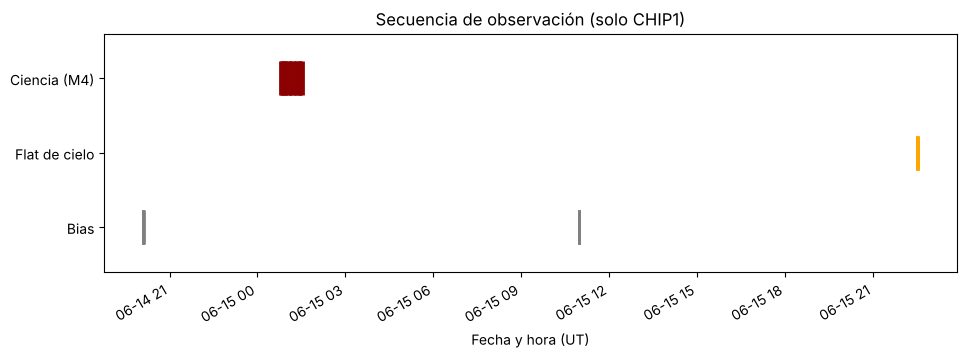

In [8]:
from astropy.time import Time

fig, ax = plt.subplots(figsize=(11, 3.5))
colores = {"BIAS": "gray", "FLAT,SKY": "orange", "OBJECT": "darkred"}
posicion = {"BIAS": 0, "FLAT,SKY": 1, "OBJECT": 2}

for fila in inventario[inventario["chip"] == "CHIP1"]:
    if fila["tipo"] == "BIAS" and not (INICIO_NOCHE < fila["fecha"] < FIN_NOCHE):
        continue   # no graficamos los bias de otras noches
    t = Time(fila["fecha"])
    ax.plot(t.datetime, posicion[fila["tipo"]], "|", color=colores[fila["tipo"]], markersize=25, mew=2)

ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["Bias", "Flat de cielo", "Ciencia (M4)"])
ax.set_ylim(-0.6, 2.6)
ax.set_xlabel("Fecha y hora (UT)")
ax.set_title("Secuencia de observación (solo CHIP1)")
fig.autofmt_xdate()
plt.show()

### 2.5 Las condiciones durante la secuencia

Las 25 exposiciones de ciencia duran **52 s** cada una. Veamos cómo cambiaron la masa de aire y el seeing a lo largo de la secuencia.

Tiempo de exposición de cada imagen: {np.float64(51.98), np.float64(51.99), np.float64(52.0), np.float64(52.01)} s
Tiempo total sobre el objeto: 1299.88 s


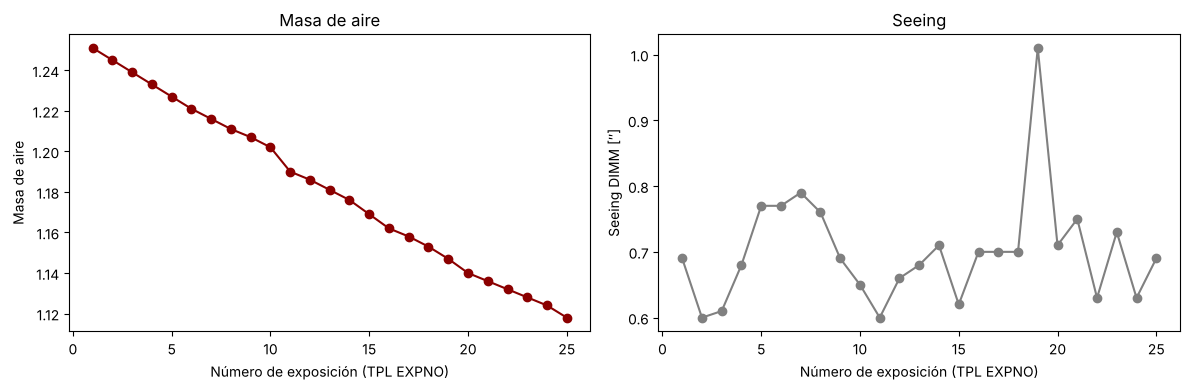

In [9]:
ciencia1 = inventario[(inventario["tipo"] == "OBJECT") & (inventario["chip"] == "CHIP1")]

print("Tiempo de exposición de cada imagen:", set(ciencia1["exptime"]), "s")
print("Tiempo total sobre el objeto:", np.sum(ciencia1["exptime"]), "s")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ciencia1["expno"], ciencia1["airmass"], "o-", color="darkred")
ax[0].set_xlabel("Número de exposición (TPL EXPNO)")
ax[0].set_ylabel("Masa de aire")
ax[0].set_title("Masa de aire")

ax[1].plot(ciencia1["expno"], ciencia1["seeing"], "o-", color="gray")
ax[1].set_xlabel("Número de exposición (TPL EXPNO)")
ax[1].set_ylabel("Seeing DIMM [″]")
ax[1].set_title("Seeing")
plt.tight_layout()
plt.show()

### 2.6 El patrón de *jitter*

Entre una exposición y la siguiente, el telescopio se mueve un poco. Esto se llama ***jitter*** (o *dithering*) y sirve para:

1. **Rellenar el espacio entre los dos chips** (el *gap*) y los pixeles malos.
2. Que una estrella no caiga siempre en el mismo pixel → se promedian defectos del detector.
3. Poder eliminar rayos cósmicos al combinar.

Calculemos el desplazamiento de cada exposición respecto a la primera usando `RA` y `DEC` del header. Ojo: un desplazamiento en ascensión recta se multiplica por $\cos\delta$ para obtener un ángulo real en el cielo.

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `np.radians(x)` | Convierte grados a radianes (las funciones trigonométricas de numpy usan radianes). |
| `np.cos(x)` | Coseno. El factor $\cos\delta$ corrige que los círculos de ascensión recta se juntan hacia los polos. |
| `* 3600` | De grados a segundos de arco. |
| `ax.scatter(x, y, c=valores, cmap="Reds")` | Puntos coloreados según `valores` (aquí, el número de exposición). |
| `ax.invert_xaxis()` | Invierte el eje x: en el cielo el Este queda a la izquierda. |
| `ax.set_aspect("equal")` | Misma escala en x y en y, para que el patrón no se deforme. |
| `np.diff(x)` | Diferencias entre elementos consecutivos: `[1, 4, 9]` → `[3, 5]`. |
| `np.ptp(x)` | "*Peak to peak*": máximo − mínimo. |

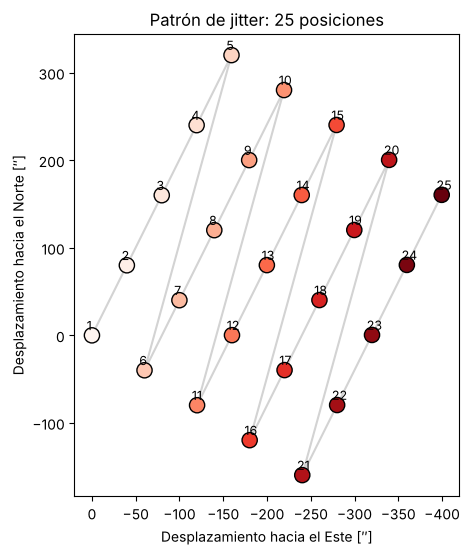

Paso típico en Norte-Sur: 80.1″
Extensión total del patrón: 400″ (E-O) x 480″ (N-S)


In [10]:
ra0 = ciencia1["ra"][0]
dec0 = ciencia1["dec"][0]

# desplazamientos en segundos de arco
d_este = (ciencia1["ra"] - ra0) * np.cos(np.radians(dec0)) * 3600
d_norte = (ciencia1["dec"] - dec0) * 3600

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(d_este, d_norte, "-", color="lightgray")
ax.scatter(d_este, d_norte, c=ciencia1["expno"], cmap="Reds", s=120, edgecolor="k", zorder=3)
for i in range(len(ciencia1)):
    ax.text(d_este[i] + 6, d_norte[i] + 6, str(ciencia1["expno"][i]), fontsize=9)
ax.invert_xaxis()   # en el cielo el Este está a la izquierda
ax.set_xlabel("Desplazamiento hacia el Este [″]")
ax.set_ylabel("Desplazamiento hacia el Norte [″]")
ax.set_title("Patrón de jitter: 25 posiciones")
ax.set_aspect("equal")
plt.show()

print(f"Paso típico en Norte-Sur: {np.median(np.abs(np.diff(d_norte))):.1f}″")
print(f"Extensión total del patrón: {np.ptp(d_este):.0f}″ (E-O) x {np.ptp(d_norte):.0f}″ (N-S)")

Es una grilla de **5 × 5 posiciones** separadas por ~40″ en E-O y ~80″ en N-S. Como cada chip cubre ~8,6′ × 4,3′, la imagen combinada final cubrirá un campo **más grande** que un solo chip.

Con la información astrométrica del header (WCS) podemos dibujar dónde cayó cada chip en el cielo:

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `WCS(header)` | (astropy) Lee la **solución astrométrica** del header (`CRVAL`, `CRPIX`, `CD`): la "regla" que traduce pixeles a coordenadas del cielo. |
| `.calc_footprint()` | Devuelve las coordenadas (RA, Dec) de las **4 esquinas** de la imagen. |
| `np.vstack([a, b])` | Pega arreglos uno **debajo** del otro. Aquí repetimos la primera esquina al final para cerrar el rectángulo. |
| `ax.plot([], [], label=...)` | Una línea vacía: solo sirve para que aparezca en la leyenda. |

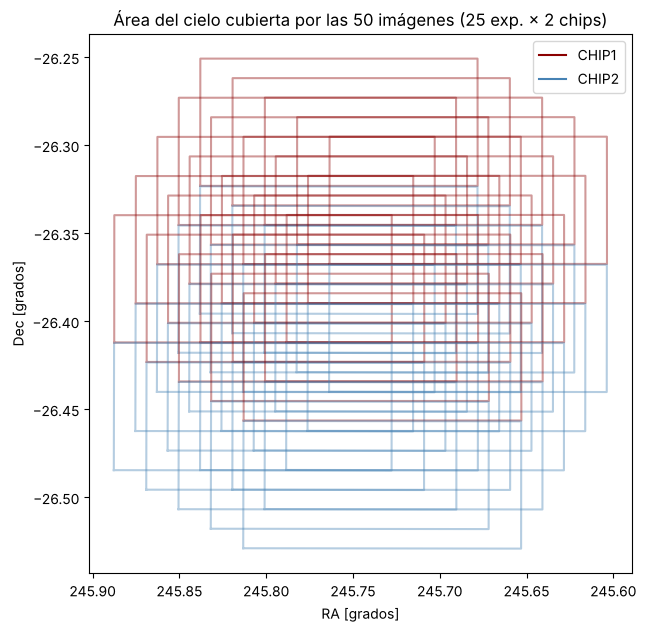

In [11]:
fig, ax = plt.subplots(figsize=(7, 7))
for fila in inventario[inventario["tipo"] == "OBJECT"]:
    datos, h = abrir_fits(fila["ruta"])
    esquinas = WCS(h).calc_footprint()          # (RA, Dec) de las 4 esquinas del chip
    esquinas = np.vstack([esquinas, esquinas[0]])  # cerramos el rectángulo
    color = "darkred" if fila["chip"] == "CHIP1" else "steelblue"
    ax.plot(esquinas[:, 0], esquinas[:, 1], color=color, alpha=0.4)

ax.plot([], [], color="darkred", label="CHIP1")
ax.plot([], [], color="steelblue", label="CHIP2")
ax.invert_xaxis()
ax.set_xlabel("RA [grados]")
ax.set_ylabel("Dec [grados]")
ax.set_title("Área del cielo cubierta por las 50 imágenes (25 exp. × 2 chips)")
ax.legend()
plt.show()

---
## Paso 3 — Anatomía de una imagen cruda

Antes de calibrar, miremos con cuidado una imagen cruda. Usamos la **primera exposición**, con sus dos chips. Para mostrarlas usamos la escala **zscale**, que realza el cielo y las estrellas débiles.

#### 🔎 Funciones nuevas en la celda siguiente

**Escalas de visualización (astropy.visualization)**

Una imagen astronómica va de ~1 500 ADU (cielo) a 65 535 ADU (estrellas saturadas). Si la mostramos de forma lineal entre el mínimo y el máximo, todo se ve negro salvo las estrellas más brillantes.

| Función | Qué hace |
|---|---|
| `ZScaleInterval()` | Elige automáticamente un rango de valores centrado en el **cielo** (el mismo algoritmo de IRAF y DS9). Ideal para ver estrellas débiles y defectos. |
| `ImageNormalize(imagen, interval=...)` | Prepara la "normalización" que usará `imshow` para pasar valores a colores. |
| `simple_norm(imagen, "asinh", percent=99.5)` | Escala no lineal (arco seno hiperbólico): comprime las estrellas brillantes sin perder las débiles. Usa el 99,5 % de los pixeles para fijar el rango. |
| `plt.colorbar(im, fraction=0.025)` | Barra de colores; `fraction` controla su ancho. |

Además, `ax=None` en la definición es un **argumento opcional**: si no le damos un `ax`, la función crea su propia figura.

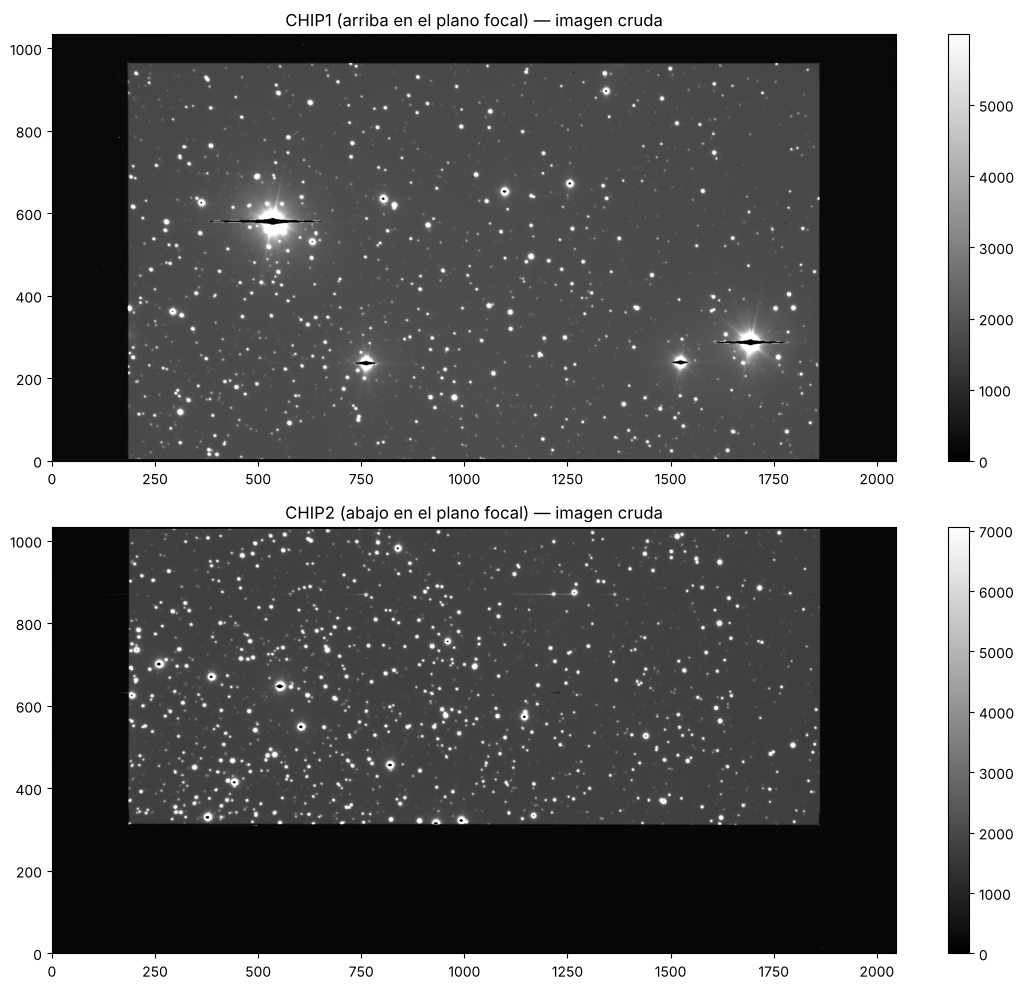

In [12]:
def mostrar(imagen, titulo="", ax=None, escala="zscale"):
    # Muestra una imagen astronómica con una escala adecuada.
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    if escala == "zscale":
        norma = ImageNormalize(imagen, interval=ZScaleInterval())
    else:
        norma = simple_norm(imagen, "asinh", percent=99.5)
    im = ax.imshow(imagen, cmap="gray", norm=norma)
    ax.set_title(titulo)
    plt.colorbar(im, ax=ax, fraction=0.025)
    return ax


primera = ciencia[ciencia["expno"] == 1]
crudo1, h1 = abrir_fits(primera[primera["chip"] == "CHIP1"]["ruta"][0])
crudo2, h2 = abrir_fits(primera[primera["chip"] == "CHIP2"]["ruta"][0])

fig, ax = plt.subplots(2, 1, figsize=(11, 10))
mostrar(crudo1, "CHIP1 (arriba en el plano focal) — imagen cruda", ax=ax[0])
mostrar(crudo2, "CHIP2 (abajo en el plano focal) — imagen cruda", ax=ax[1])
plt.tight_layout()
plt.show()

### 3.1 Prescan y overscan

Las primeras y las últimas 5 filas **no son pixeles expuestos a la luz**: son lecturas "en vacío" del registro. Su valor es solo el **nivel de bias**. Veamos el valor mediano de cada fila:

#### 🔎 Funciones nuevas en la celda siguiente

**El parámetro `axis`** (muy importante en todo el notebook)

Una imagen es un arreglo 2D de forma `(filas, columnas)` = `(1034, 2048)`.

* `np.median(imagen)` → **un solo número**: la mediana de todos los pixeles.
* `np.median(imagen, axis=1)` → recorre cada **fila** a lo largo de las columnas → 1034 números (uno por fila).
* `np.median(imagen, axis=0)` → recorre cada **columna** a lo largo de las filas → 2048 números (uno por columna).

Otras funciones de esta celda:

| Función | Qué hace |
|---|---|
| `crudo1[0:5, :]` | *Slicing*: filas 0 a 4 (el 5 **no** se incluye) y todas las columnas (`:`). |
| `crudo1[-5:, :]` | Las **últimas** 5 filas (los índices negativos cuentan desde el final). |
| `np.arange(0, 20)` | Números enteros de 0 a 19. |
| `ax.axvspan(a, b)` | Pinta una franja vertical entre x = a y x = b. |

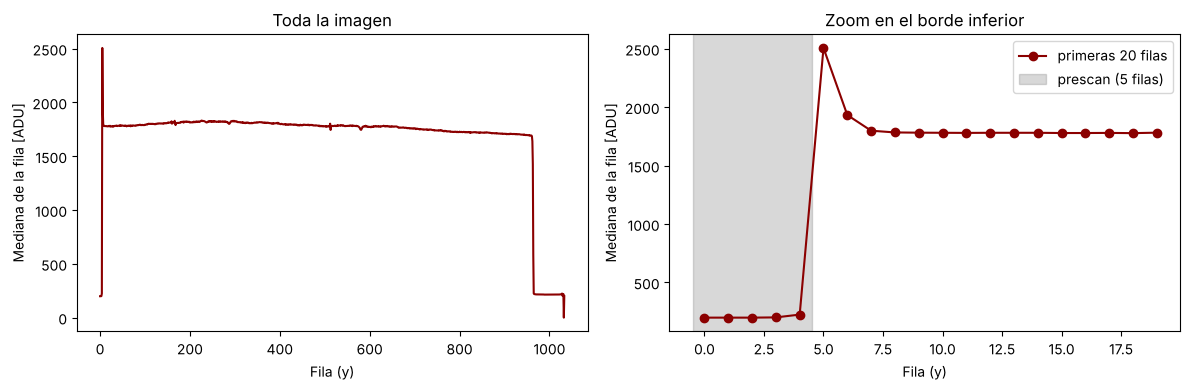

Nivel en el prescan (filas 0-4):      200.0 ADU
Nivel en el overscan (últimas 5):     201.0 ADU
Nivel típico del cielo en la imagen:  1764.0 ADU


In [13]:
mediana_por_fila = np.median(crudo1, axis=1)    # axis=1: mediana a lo largo de cada fila

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(mediana_por_fila, color="darkred")
ax[0].set_xlabel("Fila (y)")
ax[0].set_ylabel("Mediana de la fila [ADU]")
ax[0].set_title("Toda la imagen")

ax[1].plot(np.arange(0, 20), mediana_por_fila[0:20], "o-", color="darkred", label="primeras 20 filas")
ax[1].axvspan(-0.5, 4.5, color="gray", alpha=0.3, label="prescan (5 filas)")
ax[1].set_xlabel("Fila (y)")
ax[1].set_ylabel("Mediana de la fila [ADU]")
ax[1].set_title("Zoom en el borde inferior")
ax[1].legend()
plt.tight_layout()
plt.show()

print("Nivel en el prescan (filas 0-4):     ", np.median(crudo1[0:5, :]), "ADU")
print("Nivel en el overscan (últimas 5):    ", np.median(crudo1[-5:, :]), "ADU")
print("Nivel típico del cielo en la imagen: ", np.median(crudo1[5:-5, :]), "ADU")

### 3.2 Zona no iluminada y saturación

* Las **franjas negras** a la izquierda, a la derecha y en un borde de cada chip (arriba en el CHIP1, abajo en el CHIP2) son la **zona no iluminada**: el campo de FORS2 con este colimador es más pequeño que el mosaico de detectores, así que esos pixeles nunca reciben luz. En el gráfico de las filas se ve como la caída brusca cerca de la fila ~960. Esos pixeles hay que descartarlos (lo haremos con el flat).
* Las estrellas más brillantes del cúmulo **saturan**: el convertidor analógico-digital tiene 16 bits, así que el valor máximo posible es $2^{16}-1 = 65535$ ADU. En esos pixeles **no conocemos** el flujo real.

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `np.sum(crudo1 >= 65535)` | `crudo1 >= 65535` da una imagen de `True`/`False`; al sumarla contamos los pixeles saturados. |
| `crudo1.ravel()` | "Aplana" la imagen 2D en una lista 1D de 2 millones de valores, que es lo que necesita un histograma. |
| `plt.hist(..., log=True)` | Histograma con eje y logarítmico, para ver a la vez los millones de pixeles de cielo y los pocos saturados. |
| `plt.axvline(x)` | Línea vertical en x. |

Valor máximo de la imagen: 65535.0 ADU
Pixeles saturados (= 65535):   868
Pixeles sobre 60000 ADU:      1027


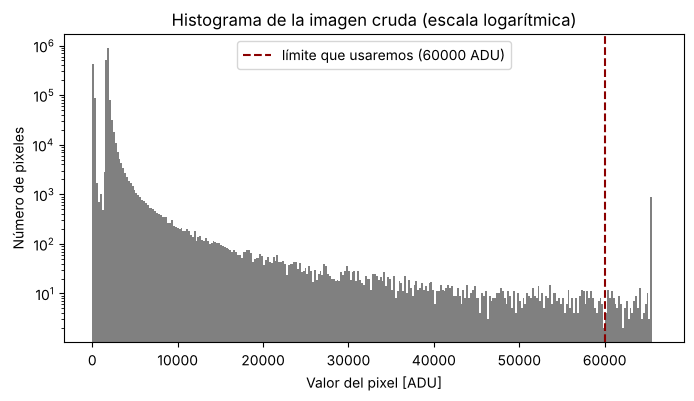

In [14]:
SATURACION = 60000   # ADU: por encima de esto el detector ya no es lineal; marcamos esos pixeles

n_saturados = np.sum(crudo1 >= 65535)
n_no_lineales = np.sum(crudo1 >= SATURACION)
print("Valor máximo de la imagen:", crudo1.max(), "ADU")
print("Pixeles saturados (= 65535):  ", n_saturados)
print("Pixeles sobre", SATURACION, "ADU:     ", n_no_lineales)

plt.figure(figsize=(8, 4))
plt.hist(crudo1.ravel(), bins=300, range=(0, 66000), color="gray", log=True)
plt.axvline(SATURACION, color="darkred", ls="--", label=f"límite que usaremos ({SATURACION} ADU)")
plt.xlabel("Valor del pixel [ADU]")
plt.ylabel("Número de pixeles")
plt.title("Histograma de la imagen cruda (escala logarítmica)")
plt.legend()
plt.show()

---
## Paso 4 — Bias

El **bias** es una imagen de **0 segundos** de exposición: el obturador no se abre. Mide el nivel electrónico que el detector suma a **todos** los pixeles (para que la señal nunca sea negativa).

### 4.1 Un bias individual

#### 🔎 Funciones nuevas en la celda siguiente

**`sigma_clipped_stats` (astropy.stats): la función estadística más importante del notebook**

Calcula **media, mediana y desviación estándar** de forma **robusta**:

1. Calcula la mediana y la desviación estándar.
2. **Descarta** los valores que se alejan más de 3σ (pixeles calientes, rayos cósmicos, estrellas).
3. Repite hasta que no se descarte nada más.

Devuelve tres valores, que separamos con `media, mediana, desv = ...`. Ignora automáticamente los `NaN`.

Opciones que usaremos: `sigma=3` (umbral de corte) y `axis=0` (para combinar imágenes, en el paso 10).

EXPTIME del bias: 0.0 s
Media = 198.39 ADU   Mediana = 198.00 ADU   Desv. estándar = 2.46 ADU


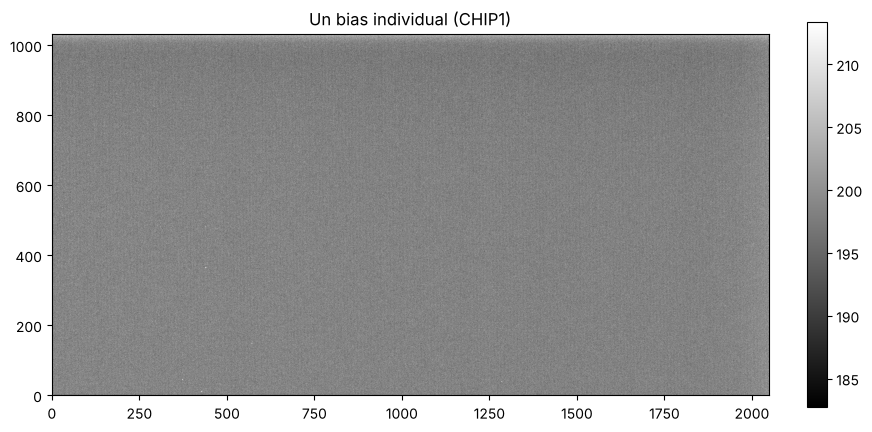

In [15]:
bias_chip1 = bias_noche[bias_noche["chip"] == "CHIP1"]
bias_chip2 = bias_noche[bias_noche["chip"] == "CHIP2"]

un_bias, h_bias = abrir_fits(bias_chip1["ruta"][0])
print("EXPTIME del bias:", h_bias["EXPTIME"], "s")

media, mediana, desv = sigma_clipped_stats(un_bias)
print(f"Media = {media:.2f} ADU   Mediana = {mediana:.2f} ADU   Desv. estándar = {desv:.2f} ADU")

mostrar(un_bias, "Un bias individual (CHIP1)")
plt.show()

Un bias se ve como **ruido**: su desviación estándar es el **ruido de lectura** (más un poco de estructura fija).

### 4.2 Medir el ruido de lectura nosotros mismos

Si restamos **dos** bias, se cancela todo lo que es igual en ambos (el nivel y la estructura fija) y queda solo el ruido. Como la diferencia de dos variables aleatorias tiene varianza doble:

$$\sigma_{\rm RON} = \frac{\sigma(B_1 - B_2)}{\sqrt{2}} \quad [\text{ADU}] \qquad\Longrightarrow\qquad \sigma_{\rm RON}\,[e^-] = \sigma_{\rm RON}\,[\text{ADU}] \times g$$

donde $g$ es la ganancia en e⁻/ADU.

#### 🔎 Funciones nuevas en la celda siguiente

* `GANANCIA = {"CHIP1": ..., "CHIP2": ...}` es un **diccionario**: guardamos un valor por chip y lo pedimos con `GANANCIA["CHIP1"]`.
* `for chip, tabla in [("CHIP1", bias_chip1), ("CHIP2", bias_chip2)]:` recorre una lista de **pares**; en cada vuelta, `chip` toma el primer elemento del par y `tabla` el segundo.
* `np.sqrt(2)`: raíz cuadrada.
* `diferencia[5:-5, :]`: todas las filas menos las 5 primeras y las 5 últimas (prescan y overscan).

In [16]:
GANANCIA = {"CHIP1": h1["HIERARCH ESO DET OUT1 CONAD"], "CHIP2": h2["HIERARCH ESO DET OUT1 CONAD"]}
RON_HEADER = {"CHIP1": h1["HIERARCH ESO DET OUT1 RON"], "CHIP2": h2["HIERARCH ESO DET OUT1 RON"]}

for chip, tabla in [("CHIP1", bias_chip1), ("CHIP2", bias_chip2)]:
    b1, _ = abrir_fits(tabla["ruta"][0])
    b2, _ = abrir_fits(tabla["ruta"][1])
    diferencia = b1 - b2
    # usamos sigma-clipping para que los pocos pixeles calientes no inflen la desviación
    _, _, sigma_dif = sigma_clipped_stats(diferencia[5:-5, :])
    ron_adu = sigma_dif / np.sqrt(2)
    ron_e = ron_adu * GANANCIA[chip]
    print(f"{chip}: RON medido = {ron_adu:.2f} ADU = {ron_e:.2f} e-    (header: {RON_HEADER[chip]} e-)")

CHIP1: RON medido = 2.42 ADU = 3.03 e-    (header: 2.7 e-)
CHIP2: RON medido = 2.67 ADU = 3.34 e-    (header: 3.6 e-)


¡Muy parecido al valor del header! (Las diferencias de algunas décimas son normales: el header da un valor nominal.)

### 4.3 El master bias

Combinamos los 10 bias de la noche de cada chip con la **mediana pixel a pixel**. La mediana elimina valores atípicos (rayos cósmicos, si los hubiera) y reduce el ruido aproximadamente en un factor $\sqrt{N}$.

En numpy: apilamos las imágenes en un cubo de 3 dimensiones `(N, filas, columnas)` y calculamos la mediana a lo largo del eje 0.

#### 🔎 Funciones nuevas en la celda siguiente

**Apilar imágenes en un cubo y combinar con `axis=0`**

* `np.array(lista)` convierte una lista de N imágenes 2D en **un cubo 3D** de forma `(N, filas, columnas)`. Piensen en una pila de hojas.
* `cubo.shape` dice la forma del arreglo: `(10, 1034, 2048)`.
* `np.median(cubo, axis=0)` calcula la mediana **a lo largo de la pila**: para cada pixel (y, x) toma los N valores de ese pixel en las N imágenes y se queda con la mediana. El resultado es una imagen 2D.

Esta misma idea se usa para el master flat y para el *stacking*.

CHIP1


  cubo de bias: (10, 1034, 2048)


  master bias: mediana = 198.50 ADU, desv. estándar = 1.02 ADU
CHIP2
  cubo de bias: (10, 1034, 2048)


  master bias: mediana = 191.50 ADU, desv. estándar = 1.07 ADU


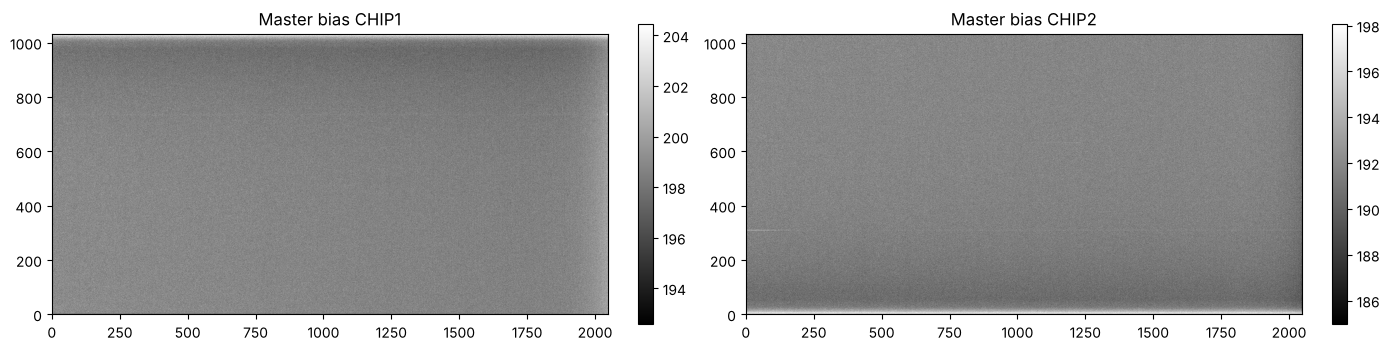

In [17]:
def crear_master_bias(tabla_bias):
    lista = []
    for ruta in tabla_bias["ruta"]:
        datos, h = abrir_fits(ruta)
        lista.append(datos)
    cubo = np.array(lista)               # forma: (N, 1034, 2048)
    print("  cubo de bias:", cubo.shape)
    master = np.median(cubo, axis=0)     # mediana pixel a pixel
    return master


master_bias = {}
for chip, tabla in [("CHIP1", bias_chip1), ("CHIP2", bias_chip2)]:
    print(chip)
    master_bias[chip] = crear_master_bias(tabla)
    _, med, sd = sigma_clipped_stats(master_bias[chip])
    print(f"  master bias: mediana = {med:.2f} ADU, desv. estándar = {sd:.2f} ADU")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
mostrar(master_bias["CHIP1"], "Master bias CHIP1", ax=ax[0])
mostrar(master_bias["CHIP2"], "Master bias CHIP2", ax=ax[1])
plt.tight_layout()
plt.show()

**Preguntas:**

* ¿Cuánto bajó la desviación estándar del master bias comparada con la de un bias individual? ¿Es cercano a $1/\sqrt{10}$?
* ¿El nivel de bias es igual en los dos chips?

### 4.4 ¿El bias cambia durante la noche?

Comparemos el nivel del master bias con el nivel del **prescan** de cada imagen de ciencia (que es el bias "en el momento" de la exposición).

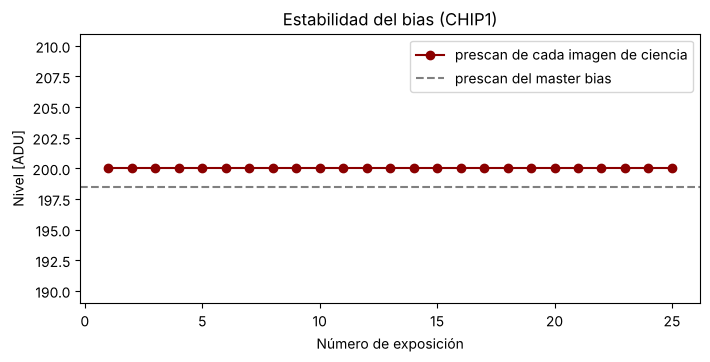

Diferencia típica: 1.5 ADU


In [18]:
nivel_master = np.median(master_bias["CHIP1"][0:5, :])
niveles_prescan = []
for ruta in ciencia1["ruta"]:
    datos, h = abrir_fits(ruta)
    niveles_prescan.append(np.median(datos[0:5, :]))

plt.figure(figsize=(8, 3.5))
plt.plot(ciencia1["expno"], niveles_prescan, "o-", color="darkred", label="prescan de cada imagen de ciencia")
plt.axhline(nivel_master, color="gray", ls="--", label="prescan del master bias")
plt.xlabel("Número de exposición")
plt.ylabel("Nivel [ADU]")
plt.title("Estabilidad del bias (CHIP1)")
plt.legend()
plt.show()

print(f"Diferencia típica: {np.median(niveles_prescan) - nivel_master:.1f} ADU")

La diferencia es de ~1 ADU, comparable con el ruido, frente a un cielo de ~1500 ADU: el bias de FORS2 es **muy estable** y basta con restar el master bias. En detectores menos estables se corrige además el nivel de cada imagen con su overscan (lo dejamos como ejercicio).

---
## Paso 5 — Dark: ¿lo necesitamos?

La **corriente oscura** son electrones generados por la temperatura del detector, que se acumulan con el tiempo ($D \cdot t$).

* En la carpeta **no hay darks**.
* Los CCD de FORS2 se enfrían con **nitrógeno líquido** a unos −120 °C. A esa temperatura la corriente oscura es del orden de **unos pocos electrones por pixel por hora**.
* Nuestras exposiciones duran **52 s**. Hagamos la cuenta con un valor generoso:

In [19]:
corriente_oscura = 5.0     # e-/pixel/hora (valor "generoso" para un CCD enfriado con N2 líquido)
t_exp = 52.0               # s

dark_e = corriente_oscura * t_exp / 3600
print(f"Electrones de dark en {t_exp:.0f} s: {dark_e:.2f} e- por pixel")
print(f"Ruido de lectura:                 {RON_HEADER['CHIP1']} e- por pixel")
print(f"Cielo en la imagen:              ~{(np.median(crudo1) - nivel_master) * GANANCIA['CHIP1']:.0f} e- por pixel")

Electrones de dark en 52 s: 0.07 e- por pixel
Ruido de lectura:                 2.7 e- por pixel
Cielo en la imagen:              ~1954 e- por pixel


El dark aporta **mucho menos de 1 electrón**, despreciable frente al ruido de lectura y al cielo. Por eso **no hacemos corrección de dark**: nuestra ecuación queda

$$\text{Objeto} + \text{Cielo} = \frac{\text{RAW} - B}{F}$$

---
## Paso 6 — Flat

El **flat** mide la **respuesta relativa** de cada pixel: diferencias de eficiencia cuántica entre pixeles, viñeteo de la óptica y sombras de polvo ("donas"). Se obtiene iluminando el detector de forma uniforme. Aquí usamos **flats de cielo**: imágenes del cielo durante el **crepúsculo**, cuando es brillante y uniforme.

El flat depende del **filtro** (el polvo y la eficiencia cuántica dependen de la longitud de onda), así que usamos los flats de **v_HIGH**.

### 6.1 Revisar los flats individuales

In [20]:
flats = inventario[inventario["tipo"] == "FLAT,SKY"]
flats["archivo", "chip", "exptime", "fecha", "mediana", "maximo"].pprint()

           archivo             chip exptime ... mediana  maximo
----------------------------- ----- ------- ... ------- -------
FORS2.2012-06-15T22_30_06.648 CHIP1    2.24 ... 33968.0 53990.0
FORS2.2012-06-15T22_30_06.649 CHIP2    2.24 ... 33223.0 56705.0
FORS2.2012-06-15T22_30_34.940 CHIP1    2.62 ... 35456.0 56470.0
FORS2.2012-06-15T22_30_34.941 CHIP2    2.62 ... 34670.0 59142.0
FORS2.2012-06-15T22_31_03.973 CHIP1    2.95 ... 35343.0 55971.0
FORS2.2012-06-15T22_31_03.974 CHIP2    2.95 ... 34552.0 58909.0
FORS2.2012-06-15T22_31_32.946 CHIP1    3.33 ... 35549.0 56380.0
FORS2.2012-06-15T22_31_32.947 CHIP2    3.33 ... 34745.0 59419.0
FORS2.2012-06-15T22_32_02.968 CHIP1    3.72 ... 35286.0 55862.0
FORS2.2012-06-15T22_32_02.969 CHIP2    3.72 ... 34481.0 58839.0


Cosas que hay que revisar en los flats:

* **Nivel**: ~35 000 ADU. Suficiente señal (el ruido de Poisson relativo es $1/\sqrt{35000 \times 1{,}25} \approx 0{,}5\%$ por pixel en cada flat).
* **Que no estén saturados**: el máximo está bajo 65 535 ADU. Esos máximos son estrellas que se ven en el cielo del crepúsculo.
* El tiempo de exposición **aumenta** de 2 a 4 s: el cielo se oscurece durante el crepúsculo, y el sistema ajusta el tiempo para mantener un nivel parecido.

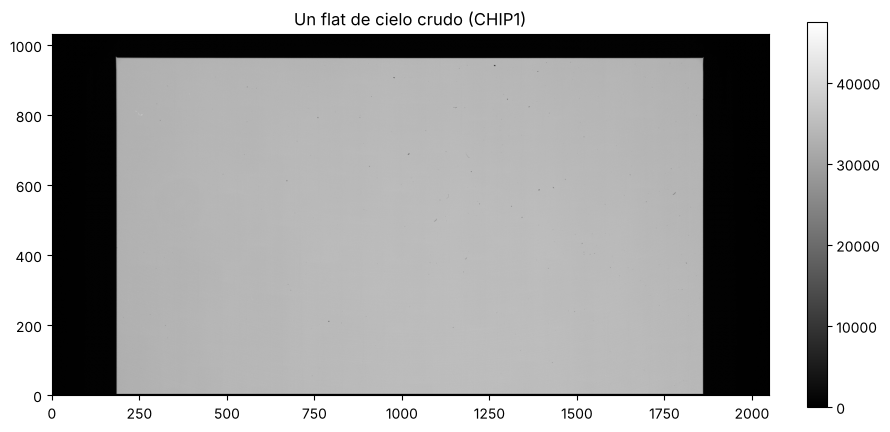

In [21]:
flats_chip1 = flats[flats["chip"] == "CHIP1"]
un_flat, _ = abrir_fits(flats_chip1["ruta"][0])
mostrar(un_flat, "Un flat de cielo crudo (CHIP1)")
plt.show()

### 6.2 El master flat paso a paso

Para cada flat:

1. **Restar el master bias** (el bias no es luz, no debe entrar en el flat).
2. **Normalizar**: dividir por su mediana en la zona central, para que el valor típico sea **1**. Así todos los flats quedan en la misma escala aunque tengan distinto nivel.

Después combinamos los flats normalizados con la **mediana**. Como el telescopio se movió entre un flat y otro, las estrellas del cielo caen en lugares distintos y **la mediana las elimina**.

Finalmente, los pixeles con respuesta < 0,5 son la **zona no iluminada** (viñeteo): los marcamos con `NaN` ("*Not a Number*"), que significa "aquí no hay dato".

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `slice(5, 1029)` | Guarda un *slicing* en una variable: `imagen[FILAS_UTILES]` es lo mismo que `imagen[5:1029]`. Así lo escribimos una sola vez y no nos equivocamos de número. |
| `ZONA_CENTRAL = (slice(...), slice(...))` | Lo mismo en 2D: `imagen[ZONA_CENTRAL]` = `imagen[300:800, 500:1500]`. |
| `master[master < 0.5] = np.nan` | **Asignar con una máscara**: a todos los pixeles donde la condición es `True` les pone `NaN`. |
| `np.nan` | "*Not a Number*": un valor especial que significa **"aquí no hay dato"**. Cualquier operación con `NaN` da `NaN`. |
| `np.isnan(x)` | `True` donde hay `NaN`. Con `np.mean(np.isnan(x))` obtenemos la **fracción** de pixeles sin dato. |
| `np.nanmedian(x)` | Mediana **ignorando** los `NaN` (`np.median` devolvería `NaN`). Hay versiones `nan` de casi todo: `np.nanmean`, `np.nanstd`, `np.nanmax`... |

In [22]:
FILAS_UTILES = slice(5, 1029)          # sin las 5 filas de prescan y las 5 de overscan
ZONA_CENTRAL = (slice(300, 800), slice(500, 1500))   # región central para normalizar

def crear_master_flat(tabla_flats, master_b):
    lista = []
    for ruta in tabla_flats["ruta"]:
        datos, h = abrir_fits(ruta)
        flat = datos - master_b                    # 1) restar el bias
        nivel = np.median(flat[ZONA_CENTRAL])      # 2) nivel típico en el centro
        flat_normalizado = flat / nivel            #    normalizar a 1
        print(f"  {os.path.basename(ruta)[:29]}  nivel = {nivel:8.1f} ADU")
        lista.append(flat_normalizado)

    cubo = np.array(lista)
    master = np.median(cubo, axis=0)               # 3) combinar con la mediana
    master[master < 0.5] = np.nan                  # 4) zona no iluminada -> sin dato
    return master


master_flat = {}
for chip in ["CHIP1", "CHIP2"]:
    print(chip)
    master_flat[chip] = crear_master_flat(flats[flats["chip"] == chip], master_bias[chip])
    zona = master_flat[chip][FILAS_UTILES]
    print(f"  mediana del master flat = {np.nanmedian(zona):.4f}")
    print(f"  fracción de pixeles sin luz (NaN) = {np.mean(np.isnan(zona)) * 100:.1f} %")

CHIP1
  FORS2.2012-06-15T22_30_06.648  nivel =  34377.0 ADU
  FORS2.2012-06-15T22_30_34.940  nivel =  35892.0 ADU
  FORS2.2012-06-15T22_31_03.973  nivel =  35779.5 ADU
  FORS2.2012-06-15T22_31_32.946  nivel =  35992.0 ADU
  FORS2.2012-06-15T22_32_02.968  nivel =  35722.5 ADU


  mediana del master flat = 0.9915
  fracción de pixeles sin luz (NaN) = 23.3 %
CHIP2
  FORS2.2012-06-15T22_30_06.649  nivel =  34485.5 ADU
  FORS2.2012-06-15T22_30_34.941  nivel =  35999.5 ADU
  FORS2.2012-06-15T22_31_03.974  nivel =  35883.0 ADU
  FORS2.2012-06-15T22_31_32.947  nivel =  36096.5 ADU
  FORS2.2012-06-15T22_32_02.969  nivel =  35823.5 ADU


  mediana del master flat = 1.0021
  fracción de pixeles sin luz (NaN) = 42.8 %


#### 🔎 Funciones nuevas en la celda siguiente

* `fig, ax = plt.subplots(2, 1)` crea una figura con **2 paneles** (2 filas, 1 columna); `ax[0]` es el de arriba y `ax[1]` el de abajo.
* `enumerate(lista)` entrega a la vez el **número** de vuelta (`i`) y el **elemento**.
* `imshow(..., vmin=0.92, vmax=1.05)` fija a mano el rango de colores: todo lo que esté bajo 0,92 se ve negro y todo lo que esté sobre 1,05, blanco.

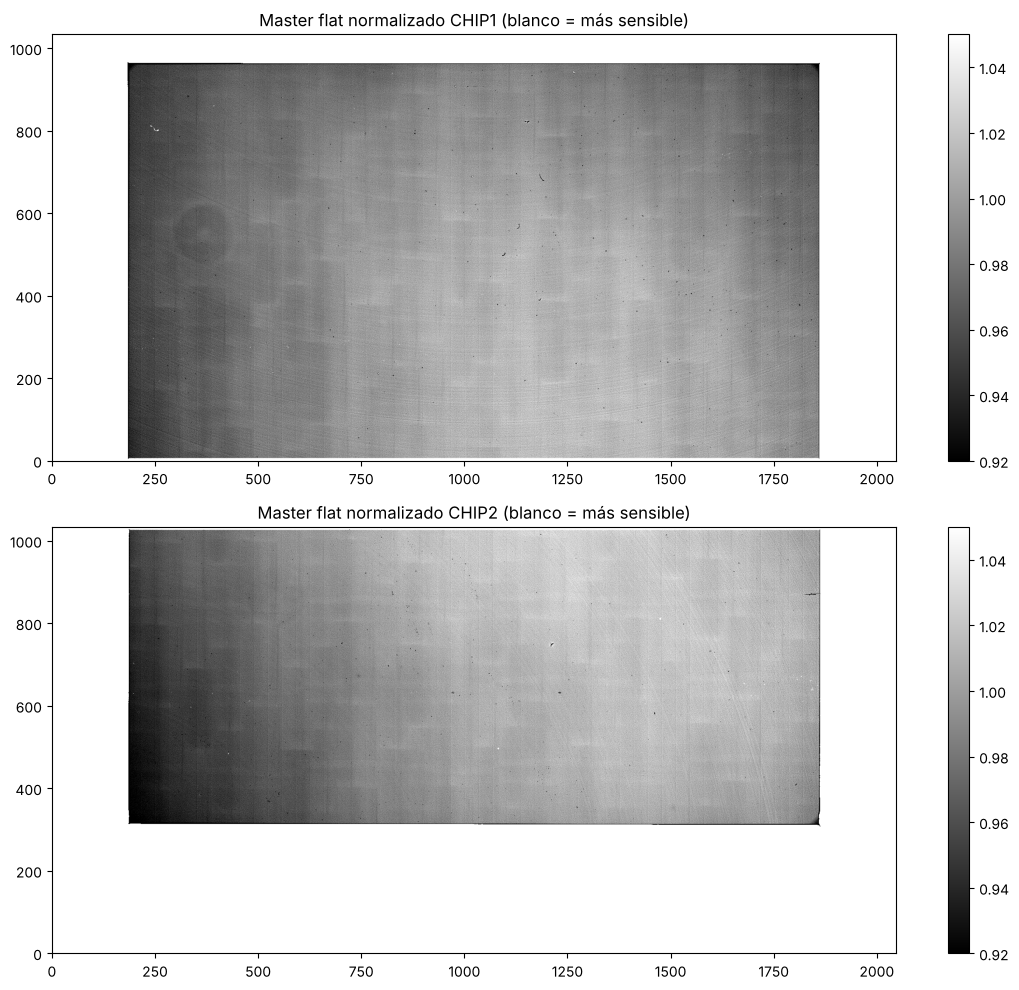

In [23]:
fig, ax = plt.subplots(2, 1, figsize=(11, 10))
for i, chip in enumerate(["CHIP1", "CHIP2"]):
    im = ax[i].imshow(master_flat[chip], cmap="gray", vmin=0.92, vmax=1.05)
    ax[i].set_title(f"Master flat normalizado {chip} (blanco = más sensible)")
    plt.colorbar(im, ax=ax[i], fraction=0.025)
plt.tight_layout()
plt.show()

**¿Qué se ve en el master flat?**

* **Viñeteo**: la respuesta cae hacia los bordes y las esquinas (las esquinas sin luz quedan en `NaN`, que matplotlib muestra en blanco o transparente).
* **"Donas"**: pequeños anillos oscuros, que son sombras de partículas de **polvo** en el filtro o en la ventana del detector, fuera de foco.
* Variaciones de **algunos %** de pixel a pixel y de una zona a otra. Sin corregirlas, ¡la magnitud de una estrella dependería de dónde cayó en el detector!

### 6.3 ¿Qué tan bueno es el master flat?

Dividamos un flat normalizado individual por el master flat. Si todo está bien, lo que queda es una imagen **plana** con valor ~1 y solo **ruido de Poisson**. Si el master tuviera estrellas o si un flat fuera distinto de los otros, aparecería aquí como manchas o gradientes.

#### 🔎 Funciones nuevas en la celda siguiente

Nada nuevo en numpy: dividir una imagen por otra se hace **pixel a pixel**. Si el flat es bueno, el cociente debería ser 1 en todas partes, salvo por ruido.

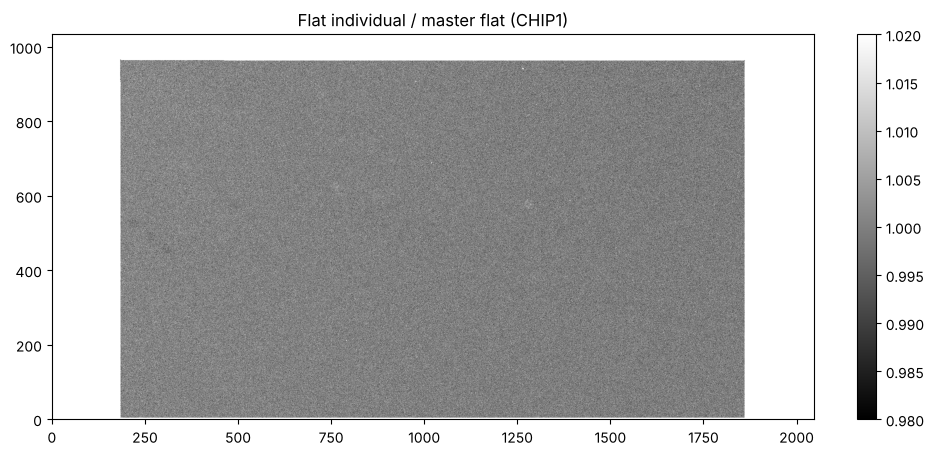

Dispersión del cociente: 0.43 %
Ruido de Poisson esperado en un flat de ~44179 e-: 0.48 %


In [24]:
flat_ind, _ = abrir_fits(flats_chip1["ruta"][0])
flat_ind = flat_ind - master_bias["CHIP1"]
flat_ind = flat_ind / np.median(flat_ind[ZONA_CENTRAL])

cociente = flat_ind / master_flat["CHIP1"]

plt.figure(figsize=(11, 5))
plt.imshow(cociente, cmap="gray", vmin=0.98, vmax=1.02)
plt.colorbar(fraction=0.025)
plt.title("Flat individual / master flat (CHIP1)")
plt.show()

_, _, sd = sigma_clipped_stats(cociente[FILAS_UTILES])
print(f"Dispersión del cociente: {sd * 100:.2f} %")
nivel_e = np.median(flats_chip1["mediana"]) * GANANCIA["CHIP1"]
print(f"Ruido de Poisson esperado en un flat de ~{nivel_e:.0f} e-: {100 / np.sqrt(nivel_e):.2f} %")

---
## Paso 7 — Calibrar una imagen de ciencia, paso a paso

Ya tenemos todo: master bias y master flat de cada chip. Ahora aplicamos la ecuación a la **primera imagen de ciencia del CHIP1**, una operación a la vez.

#### 🔎 Funciones nuevas en la celda siguiente

**¿Por qué `.copy()`?**

En numpy, `b = a` **no copia** la imagen: `a` y `b` son **la misma** imagen con dos nombres, y si modificamos `b`, también cambia `a`. Con `b = a.copy()` creamos una copia independiente.

Aquí lo usamos para poder poner `NaN` en los saturados de `paso4` sin estropear `paso3`.

Fíjense además en que cada operación es **una sola línea de numpy** que actúa sobre los 2 millones de pixeles a la vez, sin escribir ningún `for`.

In [25]:
crudo, h = abrir_fits(ciencia1["ruta"][0])
chip = h["EXTNAME"]
print("Archivo:", os.path.basename(ciencia1["ruta"][0]), "| chip:", chip, "| EXPTIME:", h["EXPTIME"], "s")

# --- 1) Restar el bias
paso1 = crudo - master_bias[chip]

# --- 2) Dividir por el flat
paso2 = paso1 / master_flat[chip]

# --- 3) Recortar prescan y overscan
paso3 = paso2[FILAS_UTILES, :]

# --- 4) Marcar los pixeles saturados / no lineales como "sin dato"
saturados = crudo[FILAS_UTILES, :] >= SATURACION
paso4 = paso3.copy()
paso4[saturados] = np.nan

# --- 5) Pasar a cuentas por segundo
calibrada = paso4 / h["EXPTIME"]

print("Forma antes:", crudo.shape, " -> después:", calibrada.shape)
print("Pixeles saturados marcados:", np.sum(saturados))
print("Pixeles sin dato (NaN) en total:", np.sum(np.isnan(calibrada)))

Archivo: FORS2.2012-06-15T00_46_28.474.fits.Z | chip: CHIP1 | EXPTIME: 52.0025 s
Forma antes: (1034, 2048)  -> después: (1024, 2048)
Pixeles saturados marcados: 1027
Pixeles sin dato (NaN) en total: 490623


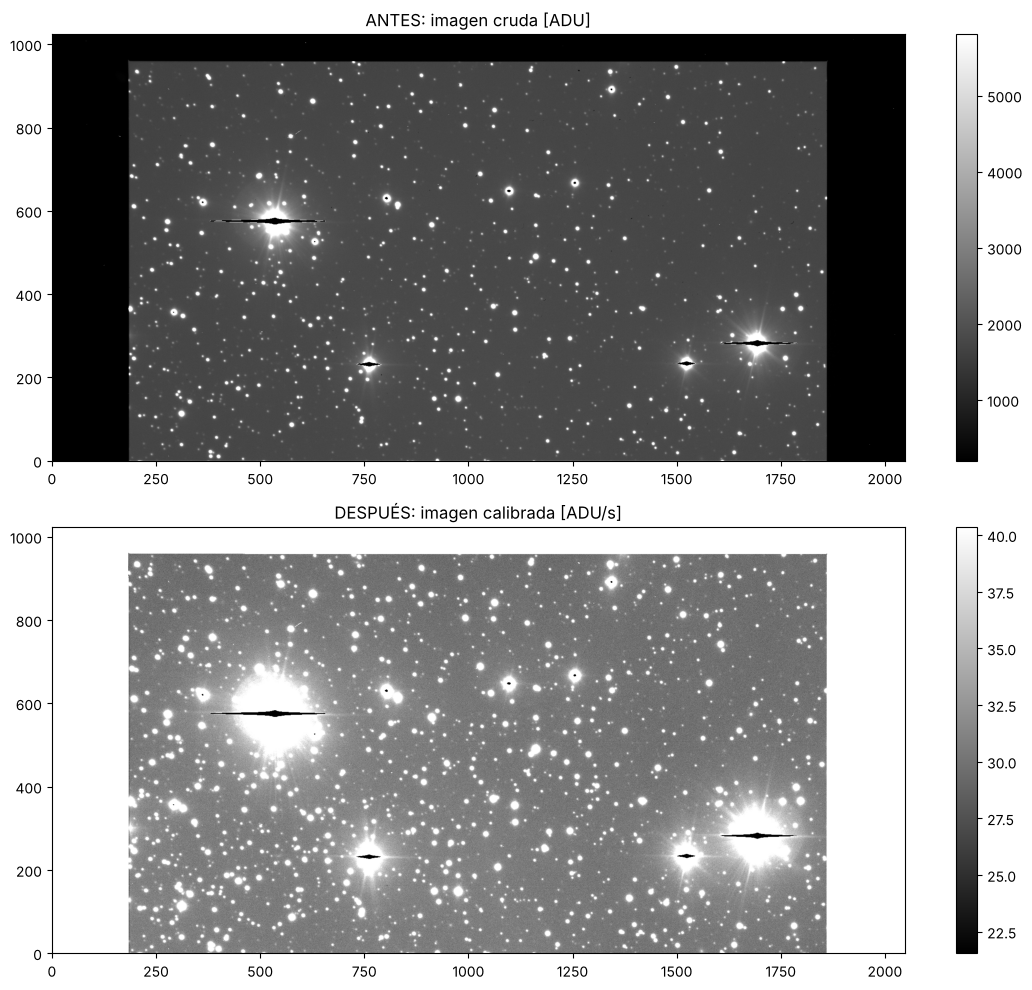

In [26]:
fig, ax = plt.subplots(2, 1, figsize=(11, 10))
mostrar(crudo[FILAS_UTILES, :], "ANTES: imagen cruda [ADU]", ax=ax[0])
mostrar(calibrada, "DESPUÉS: imagen calibrada [ADU/s]", ax=ax[1])
plt.tight_layout()
plt.show()

### 7.1 ¿Funciona el flat? La prueba con un cielo uniforme

La prueba más limpia de un flat es aplicarlo a algo que **debería** quedar perfectamente uniforme: un flat de cielo que **no** usamos para construir el master. Hacemos un master flat con 4 de los 5 flats y "calibramos" el quinto:

* **Antes** de dividir, se ven el viñeteo, el gradiente y la dona de polvo.
* **Después** de dividir, debería quedar plano, con valor ~1.

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `tabla[1:]` | Todas las filas de la tabla **menos la primera**: así el flat de prueba no participa en el master. |
| `np.where(condición, a, b)` | Elige pixel a pixel: donde la condición es `True` pone `a`, y donde es `False` pone `b`. Aquí: "deja el valor si el pixel está iluminado; si no, pon `NaN`". |
| `np.isfinite(x)` | `True` donde hay un número normal (ni `NaN` ni infinito). Es lo contrario de `np.isnan`. |

Master flat de prueba con 4 flats:
  FORS2.2012-06-15T22_30_34.940  nivel =  35892.0 ADU
  FORS2.2012-06-15T22_31_03.973  nivel =  35779.5 ADU
  FORS2.2012-06-15T22_31_32.946  nivel =  35992.0 ADU
  FORS2.2012-06-15T22_32_02.968  nivel =  35722.5 ADU


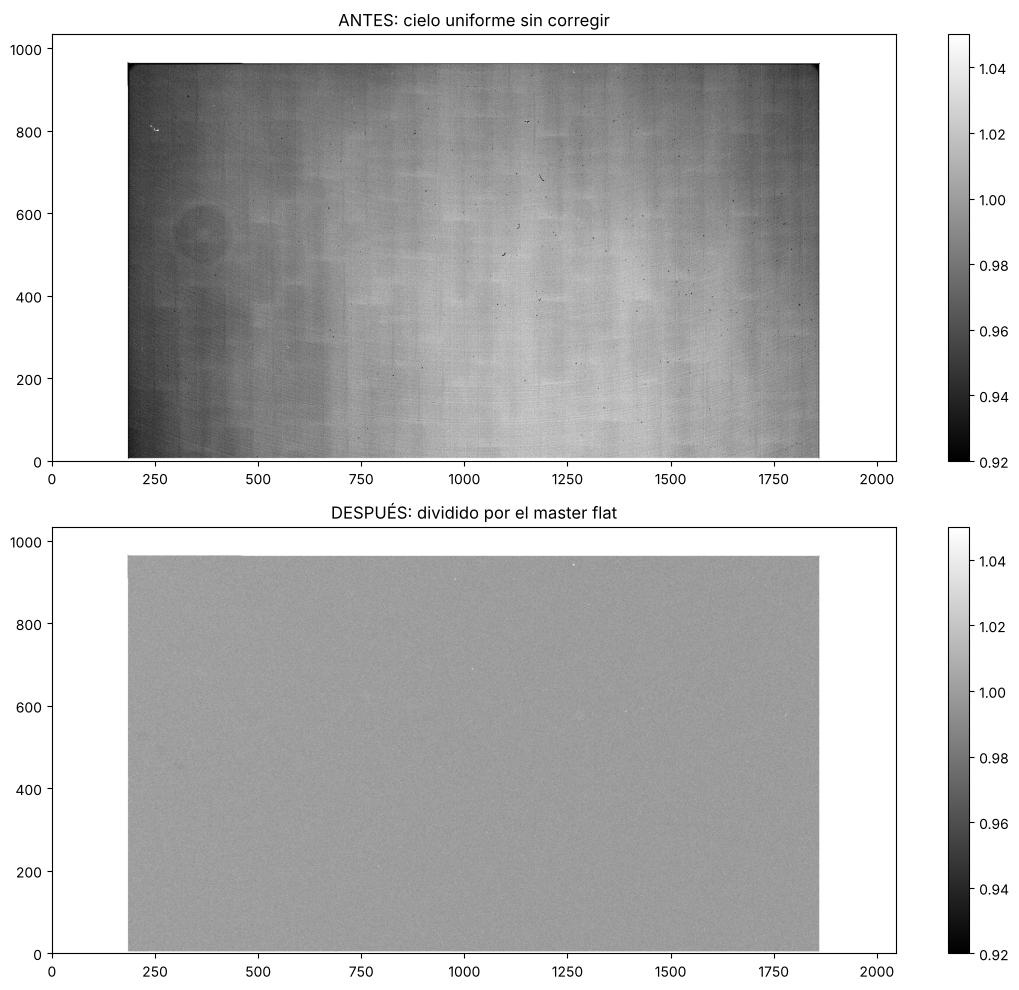

Variación del cielo ANTES:   2.0 %
Variación del cielo DESPUÉS: 0.54 %


In [27]:
flats_chip1 = flats[flats["chip"] == "CHIP1"]
print("Master flat de prueba con 4 flats:")
master_prueba = crear_master_flat(flats_chip1[1:], master_bias["CHIP1"])   # sin el primer flat

cielo_uniforme, _ = abrir_fits(flats_chip1["ruta"][0])                    # el flat que dejamos fuera
cielo_uniforme = cielo_uniforme - master_bias["CHIP1"]
antes = cielo_uniforme / np.median(cielo_uniforme[ZONA_CENTRAL])
despues = antes / master_prueba

fig, ax = plt.subplots(2, 1, figsize=(11, 10))
for i, (img, titulo) in enumerate([(antes, "ANTES: cielo uniforme sin corregir"), (despues, "DESPUÉS: dividido por el master flat")]):
    img = np.where(np.isfinite(master_prueba), img, np.nan)
    im = ax[i].imshow(img, cmap="gray", vmin=0.92, vmax=1.05)
    ax[i].set_title(titulo)
    plt.colorbar(im, ax=ax[i], fraction=0.025)
plt.tight_layout()
plt.show()

_, _, sd_antes = sigma_clipped_stats(np.where(np.isfinite(master_prueba), antes, np.nan)[FILAS_UTILES])
_, _, sd_despues = sigma_clipped_stats(despues[FILAS_UTILES])
print(f"Variación del cielo ANTES:   {sd_antes * 100:.1f} %")
print(f"Variación del cielo DESPUÉS: {sd_despues * 100:.2f} %")

El flat reduce las variaciones de ~2 % (con zonas de hasta ±5 %: el borde izquierdo, la dona de polvo, el patrón de "ladrillos" del CCD) a ~0,5 %, que es justamente el ruido de Poisson de un flat. Sin esta corrección, **la magnitud de una estrella dependería de dónde cayó en el detector**: un 5 % de error en flujo es **0,05 mag**.

> **Ojo con el cielo de M4:** en la imagen de ciencia, el "cielo" **no** queda perfectamente plano, y no es culpa del flat. M4 es un cúmulo globular: hay miles de estrellas débiles y su densidad aumenta hacia el centro del cúmulo. Esa luz se suma al fondo. Por eso probamos el flat con un cielo de crepúsculo, que sí es uniforme.

### 7.2 El nivel de cielo y su ruido

El ruido de un pixel de cielo **no** se puede medir con la desviación estándar de toda la imagen: incluiría las estrellas débiles y las variaciones del fondo del cúmulo. Un truco simple: restar cada pixel de su vecino. Las variaciones lentas del fondo se cancelan y queda solo el ruido (dividido por $\sqrt{2}$, como hicimos con los bias).

#### 🔎 Funciones nuevas en la celda siguiente

**Restar cada pixel de su vecino con slicing**

* `imagen[:, 1:]` = todas las columnas **menos la primera**.
* `imagen[:, :-1]` = todas las columnas **menos la última**.

Restarlas da, para cada pixel, **(pixel de la derecha) − (pixel)**. Las variaciones lentas del fondo (la luz del cúmulo, gradientes) son casi iguales en dos pixeles vecinos y se cancelan; lo que queda es el ruido.

In [28]:
def ruido_pixel_a_pixel(imagen):
    # Ruido de un pixel, a partir de la diferencia entre pixeles vecinos.
    diferencia = imagen[:, 1:] - imagen[:, :-1]
    _, _, desv = sigma_clipped_stats(diferencia, sigma=3)
    return desv / np.sqrt(2)


_, cielo, desv_global = sigma_clipped_stats(calibrada)
ruido_cielo = ruido_pixel_a_pixel(calibrada)
print(f"Cielo: {cielo:.2f} ADU/s  =  {cielo * h['EXPTIME']:.0f} ADU en {h['EXPTIME']:.0f} s")
print(f"Desviación estándar de toda la imagen: {desv_global:.3f} ADU/s  (incluye estrellas débiles y el fondo del cúmulo)")
print(f"Ruido de un pixel (vecino - vecino):   {ruido_cielo:.3f} ADU/s")

Cielo: 30.70 ADU/s  =  1597 ADU en 52 s
Desviación estándar de toda la imagen: 1.251 ADU/s  (incluye estrellas débiles y el fondo del cúmulo)
Ruido de un pixel (vecino - vecino):   0.742 ADU/s


---
## Paso 8 — La imagen de error

Para hacer fotometría necesitamos saber **cuánto vale la incertidumbre de cada pixel**. Según la ecuación del CCD, en electrones la varianza de un pixel es

$$\sigma^2\,[e^-] = N_{e^-} + \sigma_{\rm RON}^2$$

donde $N_{e^-}$ son los electrones de señal (estrella + cielo, ruido de Poisson). Pasando a ADU y aplicando las mismas operaciones que a la imagen (dividir por el flat y por el tiempo):

$$\sigma\,[\text{ADU/s}] = \frac{\sqrt{g \cdot (\text{RAW}-B) + \sigma_{\rm RON}^2}}{g \cdot F \cdot t}$$

#### 🔎 Funciones nuevas en la celda siguiente

* `senal_adu[senal_adu < 0] = 0`: los pixeles con valor negativo (por ruido) se ponen en 0, porque no se puede sacar raíz de una varianza negativa.
* `ron ** 2`: `**` es la **potencia** en Python ($\sigma_{\rm RON}^2$).
* `np.sqrt(...)`: raíz cuadrada pixel a pixel.

In [29]:
def imagen_error(crudo, master_b, master_f, ganancia, ron, t_exp):
    senal_adu = crudo - master_b
    senal_adu[senal_adu < 0] = 0                       # la señal no puede ser negativa
    varianza_e = ganancia * senal_adu + ron ** 2       # [e-^2]: Poisson + lectura
    sigma_adu = np.sqrt(varianza_e) / ganancia         # [ADU]
    sigma = sigma_adu / master_f / t_exp               # mismas operaciones que la imagen
    return sigma[FILAS_UTILES, :]


error = imagen_error(crudo, master_bias[chip], master_flat[chip], GANANCIA[chip], RON_HEADER[chip], h["EXPTIME"])

print(f"Error típico de un pixel de cielo: {np.nanmedian(error):.3f} ADU/s")
print(f"Ruido de un pixel medido en la imagen (paso 7.2): {ruido_cielo:.3f} ADU/s")

Error típico de un pixel de cielo: 0.694 ADU/s
Ruido de un pixel medido en la imagen (paso 7.2): 0.742 ADU/s


¡Los dos números coinciden (dentro de ~10 %)! El ruido que **medimos** en el cielo es el que **predice** la ecuación del CCD. Esto confirma que la ganancia y el ruido de lectura están bien y que el cielo está dominado por el ruido de Poisson.

---
## Paso 9 — Calibrar todas las imágenes y guardarlas

Juntamos los pasos 7 y 8 en una función y la aplicamos a las **50 imágenes** (25 exposiciones × 2 chips). Guardamos cada imagen calibrada en un FITS con:

* la extensión 0: imagen calibrada [ADU/s],
* la extensión 1: imagen de error [ADU/s],
* el header original, actualizado (`BUNIT`, `HISTORY`, y el WCS corregido por el recorte).

#### 🔎 Funciones nuevas en la celda siguiente

**Guardar FITS con astropy**

| Función | Qué hace |
|---|---|
| `h.copy()` | Copia el header (igual que con las imágenes, para no modificar el original). |
| `h_nuevo["BUNIT"] = "ADU/s"` | Agrega o cambia una palabra clave del header. |
| `h_nuevo["HISTORY"] = "..."` | Cada asignación a `HISTORY` **agrega una línea nueva** (no reemplaza). Es la "bitácora" de lo que le hicimos a la imagen. |
| `fits.PrimaryHDU(datos, header=h)` | Crea la extensión principal (imagen + header). |
| `fits.ImageHDU(datos, name="ERROR")` | Crea una extensión adicional, con nombre. Después se lee con `fits.open(archivo)["ERROR"]` o `[1]`. |
| `fits.HDUList([...]).writeto(ruta, overwrite=True, output_verify="silentfix")` | Junta las extensiones y escribe el archivo. `overwrite=True` reemplaza si ya existe; `"silentfix"` corrige sin avisar las palabras clave de ESO que no cumplen el estándar. |
| `with fits.open(ruta) as hdul:` | Abre el FITS y lo cierra al terminar el bloque (lo usamos en el paso 10). |

In [30]:
def calibrar(ruta):
    crudo, h = abrir_fits(ruta)
    chip = h["EXTNAME"]
    t = h["EXPTIME"]

    # imagen calibrada (mismos pasos del paso 7)
    imagen = (crudo - master_bias[chip]) / master_flat[chip]
    imagen = imagen[FILAS_UTILES, :]
    imagen[crudo[FILAS_UTILES, :] >= SATURACION] = np.nan
    imagen = imagen / t

    # imagen de error (paso 8)
    error = imagen_error(crudo, master_bias[chip], master_flat[chip], GANANCIA[chip], RON_HEADER[chip], t)
    error[np.isnan(imagen)] = np.nan

    # actualizar el header
    h_nuevo = h.copy()
    h_nuevo["CRPIX2"] = h["CRPIX2"] - 5      # recortamos 5 filas abajo: el pixel de referencia baja 5
    h_nuevo["BUNIT"] = "ADU/s"
    h_nuevo["HISTORY"] = "Lab. Astronomia I - Clase 5A"
    h_nuevo["HISTORY"] = "Restado master bias (mediana de 10 bias de la noche)"
    h_nuevo["HISTORY"] = "Dividido por master flat de cielo normalizado (v_HIGH)"
    h_nuevo["HISTORY"] = "Recortadas 5 filas de prescan y 5 de overscan"
    h_nuevo["HISTORY"] = f"Pixeles >= {SATURACION} ADU marcados como NaN; dividido por EXPTIME"
    return imagen, error, h_nuevo


resumen = []
for fila in inventario[inventario["tipo"] == "OBJECT"]:
    imagen, error, h_nuevo = calibrar(fila["ruta"])
    nombre = fila["archivo"] + "_cal.fits"
    hdu_imagen = fits.PrimaryHDU(imagen.astype(np.float32), header=h_nuevo)
    hdu_error = fits.ImageHDU(error.astype(np.float32), name="ERROR")
    # output_verify="silentfix": algunos keywords de ESO no cumplen el estándar FITS; astropy los arregla al guardar
    fits.HDUList([hdu_imagen, hdu_error]).writeto(os.path.join(CARPETA_CALIB, nombre), overwrite=True, output_verify="silentfix")

    _, cielo, _ = sigma_clipped_stats(imagen)
    resumen.append({"archivo": nombre, "chip": fila["chip"], "expno": fila["expno"],
                    "airmass": fila["airmass"], "cielo": cielo})

resumen = Table(rows=resumen)
print("Imágenes calibradas guardadas en:", CARPETA_CALIB)
print("Total:", len(resumen))

Imágenes calibradas guardadas en: productos_v_HIGH/calibradas
Total: 50


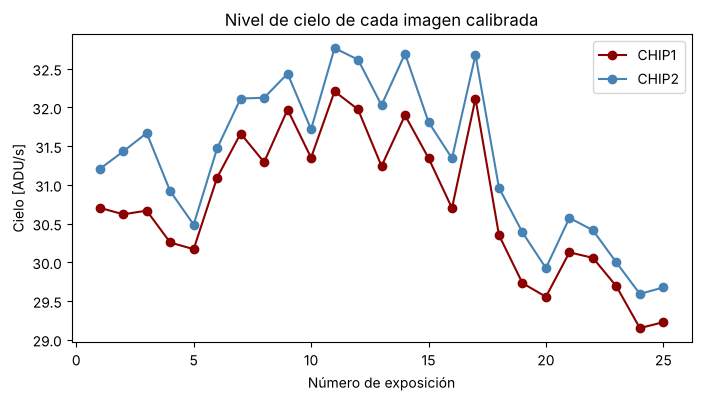

In [31]:
plt.figure(figsize=(8, 4))
for chip, color in [("CHIP1", "darkred"), ("CHIP2", "steelblue")]:
    sel = resumen[resumen["chip"] == chip]
    plt.plot(sel["expno"], sel["cielo"], "o-", color=color, label=chip)
plt.xlabel("Número de exposición")
plt.ylabel("Cielo [ADU/s]")
plt.title("Nivel de cielo de cada imagen calibrada")
plt.legend()
plt.show()

**Preguntas:**

* El cielo cambia ~10 % durante la secuencia. ¿Por qué podría cambiar el brillo del cielo en 45 minutos? (Pista: masa de aire, Luna, crepúsculo...)
* El CHIP2 da un cielo **~1–2 % más alto** que el CHIP1 en todas las exposiciones. Como normalizamos el flat de **cada chip por separado**, cada uno queda con "su propia" escala: la diferencia de sensibilidad **entre** chips no se corrige. ¿Cómo podríamos corregirla? (Pista: normalizar los dos flats por el mismo número.)

---
## Paso 10 — Combinar las exposiciones (*stacking*)

Tenemos 25 exposiciones de 52 s. Combinarlas nos da:

* **Más profundidad**: la señal crece como $N$ y el ruido como $\sqrt{N}$, así que la S/N mejora en $\sqrt{N}$ (con 25 imágenes, ¡5 veces!).
* **Eliminar rayos cósmicos**: aparecen en una sola imagen y el *sigma-clipping* los descarta.
* **Rellenar** el espacio entre chips y las zonas sin dato.

Para combinarlas hay que resolver dos problemas: **(1)** saber dónde cae cada imagen en una grilla común y **(2)** combinar los pixeles que caen en el mismo lugar.

### 10.1 Restar el cielo de cada imagen

El cielo cambia un poco de una exposición a otra (vimos el gráfico anterior). Antes de combinar, restamos el cielo de cada imagen para que todas tengan fondo 0.

In [32]:
imagenes = []   # aquí guardamos (imagen sin cielo, WCS) de cada una de las 50 imágenes
for nombre in resumen["archivo"]:
    with fits.open(os.path.join(CARPETA_CALIB, nombre)) as hdul:
        imagen = hdul[0].data
        w = WCS(hdul[0].header)
    _, cielo, _ = sigma_clipped_stats(imagen)
    imagenes.append((imagen - cielo, w))

alto, ancho = imagenes[0][0].shape
print("Imágenes cargadas:", len(imagenes), "| tamaño de cada una:", alto, "x", ancho)

Imágenes cargadas: 50 | tamaño de cada una: 1024 x 2048


### 10.2 Ubicar cada imagen con su WCS

El **WCS** (*World Coordinate System*) del header traduce **pixel → coordenadas del cielo** (RA, Dec) y viceversa. Con `astropy.wcs`:

* `w.pixel_to_world(x, y)` → coordenada en el cielo de un pixel,
* `w.world_to_pixel(coordenada)` → pixel donde cae esa coordenada.

**La idea:** tomamos la primera imagen como **referencia**. Para cada imagen, buscamos en qué pixel de la referencia cae su esquina (0, 0). Esa diferencia es el **desplazamiento** de la imagen. Como FORS2 no rota el campo entre exposiciones y la escala es la misma, basta con desplazar.

#### 🔎 Funciones nuevas en la celda siguiente

**Pasar de pixel a cielo y de cielo a pixel (astropy.wcs)**

| Función | Qué hace | Ejemplo |
|---|---|---|
| `w.pixel_to_world(x, y)` | Coordenadas en el cielo de un pixel. Devuelve un objeto `SkyCoord` con RA y Dec. | `w.pixel_to_world(0, 0)` → `<SkyCoord (ra, dec) in deg (245.85, -26.44)>` |
| `w.world_to_pixel(coordenada)` | Lo inverso: en qué pixel de **esa** imagen cae una coordenada. Puede dar valores fuera de la imagen (o negativos). | |
| `float(x)` | Convierte el resultado (un arreglo de numpy de un elemento) en un número simple. |

`imagenes[0][1]` significa: el elemento 0 de la lista (la primera imagen) y, dentro de él, la posición 1 del par `(imagen, wcs)`, es decir, su WCS.

In [33]:
wcs_ref = imagenes[0][1]

desp_x = []
desp_y = []
for imagen, w in imagenes:
    esquina_cielo = w.pixel_to_world(0, 0)               # pixel (0,0) de esta imagen -> cielo
    x, y = wcs_ref.world_to_pixel(esquina_cielo)         # cielo -> pixel de la referencia
    desp_x.append(float(x))
    desp_y.append(float(y))

desp_x = np.array(desp_x)
desp_y = np.array(desp_y)

for i in range(4):
    print(f"Imagen {i}: desplazamiento = ({desp_x[i]:8.2f}, {desp_y[i]:8.2f}) pixeles")

Imagen 0: desplazamiento = (    0.00,    -0.00) pixeles
Imagen 1: desplazamiento = (   -2.46, -1037.02) pixeles
Imagen 2: desplazamiento = (  158.73,   317.75) pixeles
Imagen 3: desplazamiento = (  156.16,  -719.27) pixeles


Ahora creamos un **lienzo** (una imagen grande vacía) donde quepan todas las imágenes. Redondeamos los desplazamientos a pixeles enteros (más simple; el error máximo es medio pixel) y dejamos un pequeño margen.

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `np.round(x).astype(int)` | Redondea y convierte a **entero**: los índices de un arreglo tienen que ser enteros. |
| `desp_x.min()`, `x0.max()` | Mínimo y máximo de un arreglo. |
| `w.deepcopy()` | Copia **completa** del WCS (igual que `.copy()` con las imágenes). |
| `w.wcs.crpix` | El pixel de referencia `(CRPIX1, CRPIX2)`. Si movemos la imagen dentro del lienzo, basta con mover este punto para que el WCS siga siendo correcto. |

In [34]:
MARGEN = 15   # pixeles extra alrededor, por si luego ajustamos la alineación

# posición (entera) de la esquina de cada imagen dentro del lienzo
x0 = np.round(desp_x - desp_x.min()).astype(int) + MARGEN
y0 = np.round(desp_y - desp_y.min()).astype(int) + MARGEN

ancho_lienzo = x0.max() + ancho + MARGEN
alto_lienzo = y0.max() + alto + MARGEN
print("Tamaño del lienzo:", alto_lienzo, "x", ancho_lienzo, "pixeles")
print(f"= {alto_lienzo * 0.252 / 60:.1f}′ x {ancho_lienzo * 0.252 / 60:.1f}′ en el cielo")

# El WCS del lienzo es el de la referencia, desplazado: su pixel (0,0) está más abajo y a la izquierda
wcs_lienzo = wcs_ref.deepcopy()
wcs_lienzo.wcs.crpix = wcs_ref.wcs.crpix + [x0[0], y0[0]]

Tamaño del lienzo: 3996 x 3668 pixeles
= 16.8′ x 15.4′ en el cielo


### 10.3 Combinar con *sigma-clipping*

Para cada pixel del lienzo tenemos entre 0 y ~25 valores (uno por cada imagen que lo cubre). Los combinamos con `astropy.stats.sigma_clipped_stats`: calcula la media **después de descartar** los valores que se alejan más de 3σ (rayos cósmicos, pixeles malos). Los `NaN` se ignoran automáticamente.

Para no usar demasiada memoria, recorremos el lienzo en **franjas** de 200 filas: para cada franja armamos un cubo `(número de imágenes, filas, columnas)` lleno de `NaN` y copiamos dentro el pedazo de cada imagen que cae en esa franja.

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `np.full(forma, np.nan, dtype=np.float32)` | Crea un arreglo de esa forma **lleno de `NaN`**: el lienzo empieza "sin datos". |
| `np.zeros(forma, dtype=np.int16)` | Arreglo lleno de ceros (enteros), para contar exposiciones. |
| `range(0, alto, 200)` | 0, 200, 400, ...: el inicio de cada franja. |
| `max(a, b)`, `min(a, b)` | Para calcular qué filas de la imagen `i` caen **dentro** de la franja. |
| `cubo[i, a:b, x0:x0+ancho] = imagen[...]` | Copia un pedazo de la imagen `i` en su lugar del cubo (*slicing* en 3D). |
| `sigma_clipped_stats(cubo, axis=0, sigma=3)` | Igual que antes, pero **a lo largo de la pila**: para cada pixel combina los ~25 valores, descarta los que se alejan más de 3σ (rayos cósmicos) e ignora los `NaN` (imágenes que no cubren ese pixel). |
| `np.sum(np.isfinite(cubo), axis=0)` | Cuenta, para cada pixel, cuántas imágenes tienen dato. |

**¿Por qué en franjas?** El lienzo tiene ~4000 × 3700 pixeles y hay 50 imágenes: un cubo completo ocuparía unos **3 GB** de memoria. Por franjas de 200 filas son unos 150 MB cada vez.

In [35]:
def combinar(imagenes, x0, y0, alto_lienzo, ancho_lienzo, filas_por_franja=200):
    combinada = np.full((alto_lienzo, ancho_lienzo), np.nan, dtype=np.float32)
    n_exp = np.zeros((alto_lienzo, ancho_lienzo), dtype=np.int16)

    for inicio in range(0, alto_lienzo, filas_por_franja):
        fin = min(inicio + filas_por_franja, alto_lienzo)
        cubo = np.full((len(imagenes), fin - inicio, ancho_lienzo), np.nan, dtype=np.float32)

        for i in range(len(imagenes)):
            imagen = imagenes[i][0]
            # filas del lienzo que ocupa la imagen i
            fila_a = max(inicio, y0[i])
            fila_b = min(fin, y0[i] + alto)
            if fila_a >= fila_b:
                continue   # esta imagen no toca esta franja
            cubo[i, fila_a - inicio:fila_b - inicio, x0[i]:x0[i] + ancho] = imagen[fila_a - y0[i]:fila_b - y0[i], :]

        media, mediana, desv = sigma_clipped_stats(cubo, axis=0, sigma=3)
        combinada[inicio:fin] = media
        n_exp[inicio:fin] = np.sum(np.isfinite(cubo), axis=0)

    return combinada, n_exp


combinada, n_exp = combinar(imagenes, x0, y0, alto_lienzo, ancho_lienzo)
print("Listo. Máximo número de imágenes en un pixel:", n_exp.max())

Listo. Máximo número de imágenes en un pixel: 23


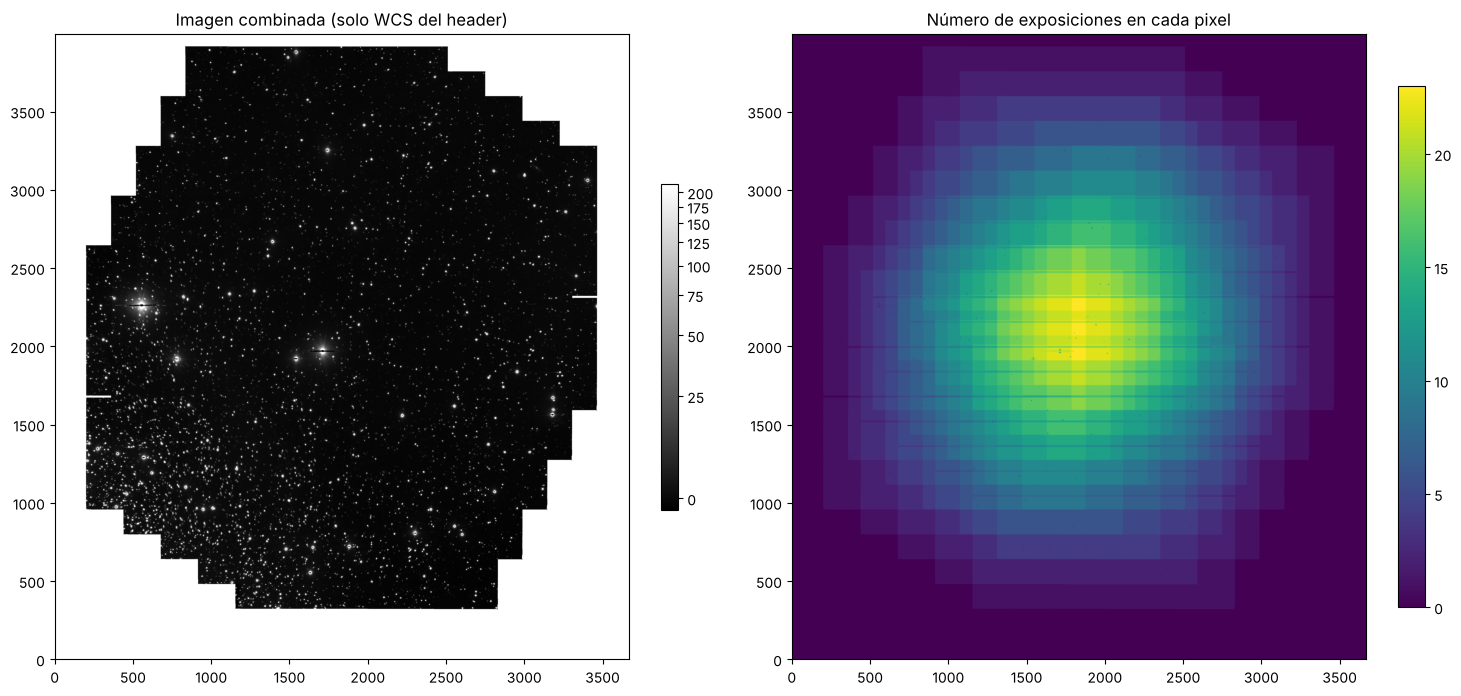

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
mostrar(combinada, "Imagen combinada (solo WCS del header)", ax=ax[0], escala="asinh")
im = ax[1].imshow(n_exp, cmap="viridis")
ax[1].set_title("Número de exposiciones en cada pixel")
plt.colorbar(im, ax=ax[1], fraction=0.04)
plt.tight_layout()
plt.show()

### 10.4 ¿Quedaron bien alineadas? Mirar de cerca

Hagamos zoom en una zona con estrellas. Si la alineación no es perfecta, las estrellas se ven **alargadas o dobles**.

#### 🔎 Funciones nuevas en la celda siguiente

* `alto_lienzo // 2`: `//` es la **división entera** (sin decimales): `7 // 2 = 3`. Los índices tienen que ser enteros.
* `zoom = (slice(...), slice(...))`: guardamos la región del zoom para usar exactamente la misma antes y después de alinear.

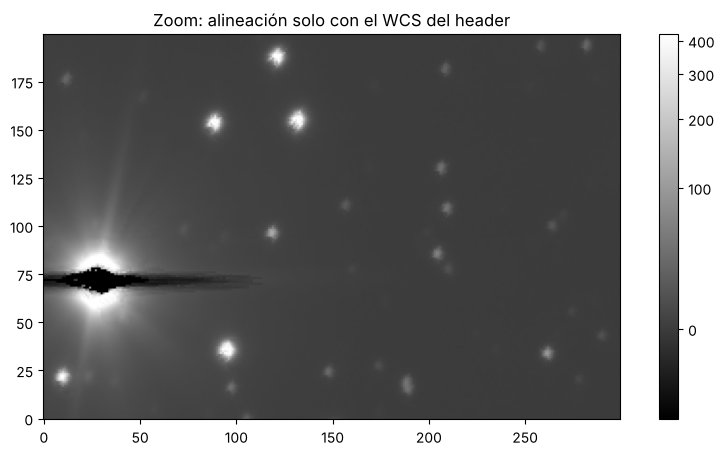

In [37]:
# zona de zoom: centro del lienzo
yc, xc = alto_lienzo // 2, ancho_lienzo // 2
zoom = (slice(yc - 100, yc + 100), slice(xc - 150, xc + 150))

mostrar(combinada[zoom], "Zoom: alineación solo con el WCS del header", escala="asinh")
plt.show()

El WCS del header de FORS2 tiene errores de **~1″ (varios pixeles)** de una imagen a otra, así que conviene **refinar** la alineación usando las propias estrellas:

1. Detectamos estrellas en la imagen combinada (con `DAOStarFinder` de `photutils`, como vimos en la clase).
2. Detectamos estrellas en cada imagen individual y calculamos dónde caen en el lienzo.
3. Emparejamos cada estrella con la más cercana de la combinada usando `SkyCoord.match_to_catalog_sky` de astropy.
4. El **desplazamiento mediano** entre las parejas es la corrección de esa imagen.
5. Volvemos a combinar. Repetimos un par de veces.

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `DAOStarFinder(fwhm=3.0, threshold=30*desv)` | (photutils) El algoritmo **DAOFIND** de DAOPHOT: busca objetos con forma de estrella de ese FWHM que superen el umbral. Primero se **configura** el buscador... |
| `buscador(imagen)` | ...y después se **aplica** a una imagen. Devuelve una tabla con `xcentroid`, `ycentroid`, `peak`, `flux`, etc. Si no encuentra nada devuelve `None`. |
| `np.nan_to_num(x)` | Cambia los `NaN` por 0, porque el detector no acepta `NaN`. |
| `cielo_i.match_to_catalog_sky(cielo_ref)` | (astropy) Para **cada** estrella de `cielo_i` busca la **más cercana** en `cielo_ref`. Devuelve tres cosas: el índice de la pareja, la separación angular y una distancia 3D que no usamos (por eso `_`). |
| `separacion < 2 * u.arcsec` | Compara ángulos **con unidades**: astropy entiende "2 segundos de arco". Así descartamos parejas falsas. |
| `ref["xcentroid"][indice[buenas]]` | Ordena las estrellas de referencia según sus parejas y se queda solo con las buenas. |
| `np.hypot(dx, dy)` | $\sqrt{dx^2 + dy^2}$: la distancia total del desplazamiento. |
| `_` | Por convención, una variable que **no vamos a usar**. |

In [38]:
from photutils.detection import DAOStarFinder

def detectar_estrellas(imagen, umbral_sigma=30):
    # Detecta estrellas brillantes (no saturadas) en una imagen con fondo ~0.
    _, mediana, desv = sigma_clipped_stats(imagen)
    buscador = DAOStarFinder(fwhm=3.0, threshold=umbral_sigma * desv)
    estrellas = buscador(np.nan_to_num(imagen - mediana))   # NaN -> 0 para el detector
    return estrellas


def medir_correcciones(imagenes, combinada, x0, y0):
    ref = detectar_estrellas(combinada)
    cielo_ref = wcs_lienzo.pixel_to_world(ref["xcentroid"], ref["ycentroid"])
    print(f"  estrellas de referencia en la combinada: {len(ref)}")

    corr_x = np.zeros(len(imagenes))
    corr_y = np.zeros(len(imagenes))
    for i in range(len(imagenes)):
        est = detectar_estrellas(imagenes[i][0])
        if est is None:
            continue
        # posición de cada estrella de la imagen i dentro del lienzo
        x_lienzo = est["xcentroid"] + x0[i]
        y_lienzo = est["ycentroid"] + y0[i]
        cielo_i = wcs_lienzo.pixel_to_world(x_lienzo, y_lienzo)

        # emparejar con la estrella más cercana de la referencia
        indice, separacion, _ = cielo_i.match_to_catalog_sky(cielo_ref)
        buenas = separacion < 2 * u.arcsec
        corr_x[i] = np.median(ref["xcentroid"][indice[buenas]] - x_lienzo[buenas])
        corr_y[i] = np.median(ref["ycentroid"][indice[buenas]] - y_lienzo[buenas])
    return corr_x, corr_y


for iteracion in range(1, 4):
    print(f"Iteración {iteracion}")
    corr_x, corr_y = medir_correcciones(imagenes, combinada, x0, y0)
    distancia = np.hypot(corr_x, corr_y)
    print(f"  corrección mediana = {np.median(distancia):.2f} px, máxima = {distancia.max():.2f} px")
    x0 = x0 + np.round(corr_x).astype(int)
    y0 = y0 + np.round(corr_y).astype(int)
    combinada, n_exp = combinar(imagenes, x0, y0, alto_lienzo, ancho_lienzo)

Iteración 1


  estrellas de referencia en la combinada: 2719


  corrección mediana = 1.47 px, máxima = 6.76 px


Iteración 2


  estrellas de referencia en la combinada: 3349


  corrección mediana = 0.43 px, máxima = 2.11 px


Iteración 3


  estrellas de referencia en la combinada: 3519


  corrección mediana = 0.39 px, máxima = 0.87 px


La corrección baja en cada iteración hasta quedar en **< 0,5 px**, que es el límite de usar desplazamientos enteros. Comparemos el zoom antes y después:

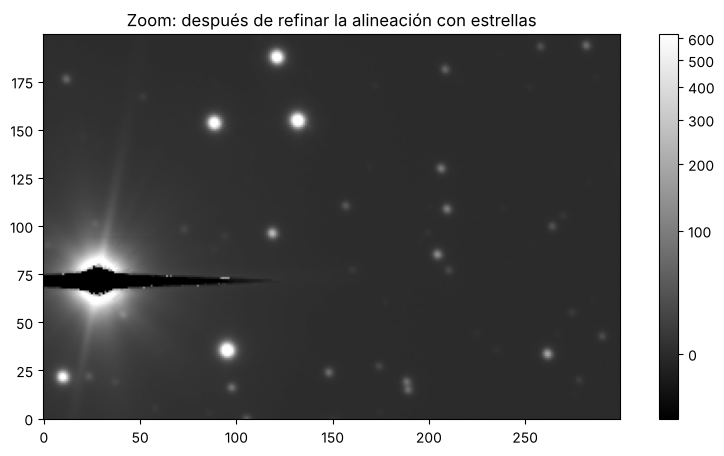

In [39]:
mostrar(combinada[zoom], "Zoom: después de refinar la alineación con estrellas", escala="asinh")
plt.show()

### 10.5 La imagen final y guardarla

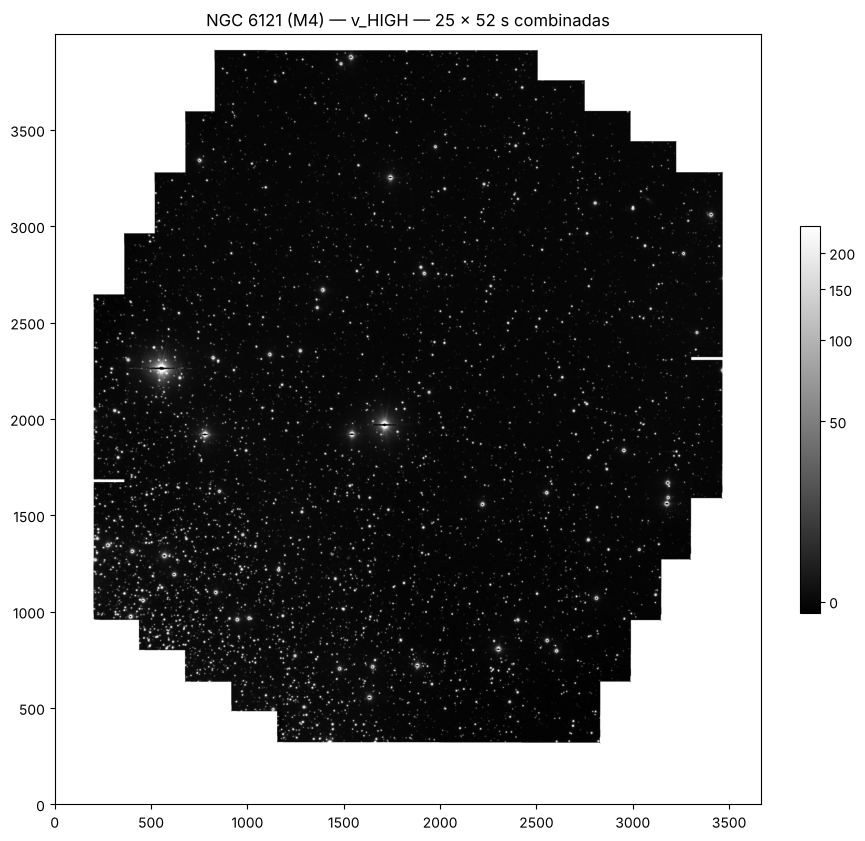

Ruido del fondo en UNA imagen:           0.7421 ADU/s
Ruido del fondo en la COMBINADA (N>=20): 0.1776 ADU/s
Mejora: 4.2 veces   (esperado ~ raíz de N ~ 4.6)


In [40]:
fig, ax = plt.subplots(figsize=(10, 10))
mostrar(combinada, "NGC 6121 (M4) — v_HIGH — 25 × 52 s combinadas", ax=ax, escala="asinh")
plt.show()

ruido_comb = ruido_pixel_a_pixel(np.where(n_exp >= 20, combinada, np.nan))
ruido_ind = ruido_pixel_a_pixel(imagenes[0][0])
print(f"Ruido del fondo en UNA imagen:           {ruido_ind:.4f} ADU/s")
print(f"Ruido del fondo en la COMBINADA (N>=20): {ruido_comb:.4f} ADU/s")
print(f"Mejora: {ruido_ind / ruido_comb:.1f} veces   (esperado ~ raíz de N ~ {np.sqrt(np.median(n_exp[n_exp >= 20])):.1f})")

#### 🔎 Funciones nuevas en la celda siguiente

| Función | Qué hace |
|---|---|
| `wcs_lienzo.to_header()` | Convierte el WCS del lienzo en un header FITS nuevo, para que la imagen combinada tenga coordenadas correctas (se puede abrir en DS9 o Aladin y ver RA/Dec). |
| `header["NCOMBINE"] = (valor, "comentario")` | Si asignamos una **tupla**, el segundo elemento queda como comentario de la palabra clave en el header. |
| `fits.writeto(ruta, datos, header, overwrite=True)` | Forma corta de guardar un FITS de una sola extensión. |

In [41]:
header_final = wcs_lienzo.to_header()
header_final["OBJECT"] = "NGC6121"
header_final["FILTER"] = FILTRO
header_final["BUNIT"] = "ADU/s"
header_final["NCOMBINE"] = (len(imagenes), "imagenes combinadas (25 exp x 2 chips)")
header_final["EXPTIME"] = (52.0, "tiempo de cada exposicion [s]; imagen en ADU/s")
header_final["HISTORY"] = "Lab. Astronomia I - Clase 5A: media sigma-clipped (3 sigma)"

fits.writeto(os.path.join(CARPETA_SALIDA, f"NGC6121_{FILTRO}_combinada.fits"), combinada, header_final, overwrite=True)
fits.writeto(os.path.join(CARPETA_SALIDA, f"NGC6121_{FILTRO}_nexp.fits"), n_exp, header_final, overwrite=True)
print("Guardado en", CARPETA_SALIDA)

Guardado en productos_v_HIGH


---
## Paso 11 — Puntos de control y ejercicios

### Lista de verificación

| Punto de control | Valor esperado | ¿OK? |
|---|---|---|
| Nivel del master bias | ~199 ADU (CHIP1), ~192 ADU (CHIP2) | |
| RON medido con dos bias | ~3 e⁻ (cercano al header) | |
| Mediana del master flat | 1,00 | |
| Cielo calibrado | plano a lo largo de la imagen (paso 7.1) | |
| Ruido medido vs. imagen de error | iguales dentro de ~10 % (paso 8) | |
| Cielo uniforme dividido por el flat | ~0,5 % de variación (paso 7.1) | |
| Alineación del stacking | corrección final < 0,5 px | |
| Mejora del ruido en la combinada | cercana a √N | |

### Ejercicios

1. **Sin flat:** calibra la primera imagen **sin** dividir por el flat. Mide el cielo en una esquina y en el centro. ¿Cuánto difieren (en %)? ¿Cuánto sería eso en magnitudes?
2. **Media vs. mediana:** construye el master bias con `np.mean` en vez de `np.median`. ¿Cambia la desviación estándar? ¿Por qué con bias casi no importa, pero con flats de cielo sí? (Pista: estrellas.)
3. **Overscan:** para cada imagen de ciencia, resta el nivel de su propio prescan en vez del master bias. ¿Cambia el resultado? ¿En qué tipo de detector sería importante?
4. **Saturación:** ¿cuántas estrellas saturadas hay en la imagen combinada? ¿Por qué no podemos hacer fotometría de ellas?
5. **Diferencia entre chips:** normaliza los flats de **ambos** chips por el nivel del CHIP1 y vuelve a calibrar. ¿Desaparece la diferencia de ~1–2 % en el cielo?
6. **Otro filtro:** repite el tutorial con `FILTRO = "b_HIGH"`. ¿Qué cambia en el master flat?
7. **Para pensar:** las 25 exposiciones se tomaron con masas de aire entre 1,25 y 1,12. ¿Afecta eso al flujo de las estrellas en cada imagen? (Lo veremos en la Unidad 6.)

### Resumen

$$\boxed{\;\text{Imagen calibrada} = \frac{\text{RAW} - \text{master bias}}{\text{master flat}} \cdot \frac{1}{t_{\rm exp}}\;}$$

Con esto, la imagen está lista para la **fotometría de apertura** (siguiente parte de la clase) y para el **punto cero con estrellas estándar** (clase 5B).

**Referencias:** Howell, *Handbook of CCD Astronomy* (2006), cap. 4; Nardiello et al. (2015), A&A 573, A70 (arXiv:1410.7503); Manual de usuario de FORS2 (ESO); Astropy CCD Data Reduction Guide.

---
## Glosario de funciones

### numpy
| Función | Qué hace |
|---|---|
| `imagen[a:b, c:d]` | *Slicing*: filas de a a b−1 y columnas de c a d−1. `:` = todas; `-5:` = las últimas 5 |
| `slice(a, b)` | Guarda un *slicing* en una variable |
| `x.astype(np.float32)` | Convierte a decimales |
| `x.copy()` | Copia independiente (sin ella, dos nombres apuntan al mismo arreglo) |
| `np.array(lista)` | Lista de imágenes → cubo 3D `(N, filas, columnas)` |
| `np.median(x, axis=...)` | Mediana; `axis=0` combina una pila de imágenes pixel a pixel |
| `np.nanmedian`, `np.nanmean` | Igual, ignorando `NaN` |
| `np.nan`, `np.isnan`, `np.isfinite` | "Sin dato" y cómo detectarlo |
| `x[condición] = valor` | Cambia solo los pixeles donde se cumple la condición |
| `np.where(cond, a, b)` | Elige `a` o `b` pixel a pixel |
| `np.sum(condición)` | Cuenta cuántos `True` hay |
| `np.full`, `np.zeros` | Arreglos llenos de un valor / de ceros |
| `np.nan_to_num` | `NaN` → 0 |
| `np.diff`, `np.ptp`, `np.hypot` | Diferencias consecutivas, máx − mín, $\sqrt{x^2+y^2}$ |
| `x.ravel()` | 2D → 1D |

### astropy
| Función | Qué hace |
|---|---|
| `fits.open(ruta)[0].data / .header` | Leer un FITS |
| `header.get(clave, por_defecto)` | Leer una palabra clave sin error si no existe |
| `fits.PrimaryHDU`, `fits.ImageHDU`, `fits.HDUList(...).writeto` | Escribir un FITS con varias extensiones |
| `Table(rows=...)` | Tabla a partir de diccionarios |
| `sigma_clipped_stats(x, sigma=3, axis=...)` | Media, mediana y σ robustas (descartan valores a > 3σ) |
| `Time(fecha)` | Fechas y escalas de tiempo |
| `WCS(header)` | Solución astrométrica |
| `w.pixel_to_world`, `w.world_to_pixel` | Pixel ↔ cielo |
| `w.calc_footprint()` | Esquinas de la imagen en el cielo |
| `w.to_header()` | WCS → header FITS |
| `SkyCoord.match_to_catalog_sky` | Emparejar estrellas por posición |
| `u.arcsec`, `u.deg` | Unidades |
| `ZScaleInterval`, `ImageNormalize`, `simple_norm` | Escalas para mostrar imágenes |

### Otras
| Función | Qué hace |
|---|---|
| `os.path.join`, `os.path.basename`, `os.path.exists`, `os.makedirs` | Rutas y carpetas |
| `glob.glob(patrón)` | Buscar archivos por nombre |
| `unlzw3.unlzw` | Descomprimir `.fits.Z` |
| `DAOStarFinder` (photutils) | Detectar estrellas (DAOFIND) |
| `f"{x:.2f}"` | Texto con números formateados |